In [139]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [140]:
# ============================================================
# PATHS REGISTRY
# AgriCLIP + E_Combined SAM2
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

# ------------------------------------------------------------
# AgriCLIP
# ------------------------------------------------------------

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

# ------------------------------------------------------------
# SAM2 — E_COMBINED CHECKPOINT
# ------------------------------------------------------------

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_augmentation_checkpoints"
    / "E_Combined.pt"
)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_E_combined_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# Verify paths
# ------------------------------------------------------------

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)
print("SAM2 checkpoint exists:", SAM2_CHECKPOINT.exists())
print("Aligner exists:", ALIGNER_PATH.exists())

Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_augmentation_checkpoints/E_Combined.pt
SAM2 checkpoint exists: True
Aligner exists: True


In [141]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [142]:
#Loading VegAnn and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [143]:
#Detecting image and mask coloums 
columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask",
    ]
)

print(IMAGE_KEY)
print(MASK_KEY)

image
mask


In [144]:
#Image helper
def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = np.array(sample[MASK_KEY])

    mask = (mask > 0).astype(np.uint8)

    return mask

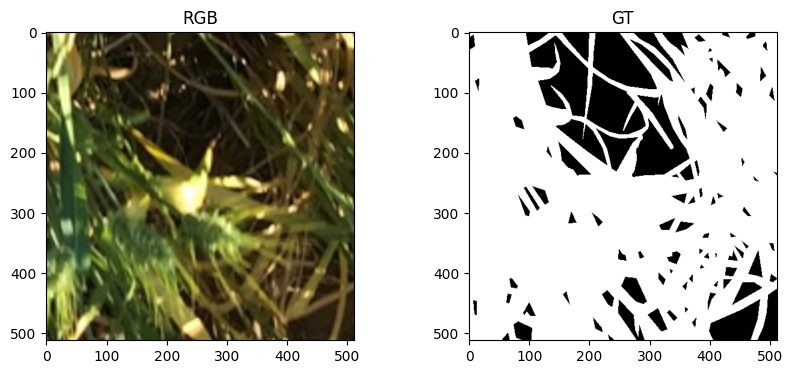

In [145]:
#Visualize image and mask 
image = get_image(0)
mask = get_mask(0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(image)
plt.title("RGB")

plt.subplot(122)
plt.imshow(mask,cmap="gray")
plt.title("GT")

plt.show()

In [146]:
#Transform the image 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

In [147]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [148]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [149]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [150]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [151]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [152]:
#Extract patches 
sample_index = 0

image = get_image(
    sample_index,
    split=val_hf,
)

gt_mask = get_mask(
    sample_index,
    split=val_hf,
)

patch_features, grid_h, grid_w = extract_dino_patch_features(
    image
)

print("Image size:", image.size)
print("Feature grid:", grid_h, "x", grid_w)
print("Patch features:", patch_features.shape)

Image size: (512, 512)
Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [153]:
print(
    "DINO feature dim:",
    patch_features.shape
)

print(
    "Aligner input:",
    aligner.W.shape
)

DINO feature dim: torch.Size([49, 2048])
Aligner input: torch.Size([512, 2048])


In [154]:
#Project patches using VegAnn aligner 
#Better to project first and then normalize in a shared concept space
@torch.no_grad()
def align_patch_features(patch_features):
    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features


aligned_patch_features = align_patch_features(
    patch_features
)

print("Aligned patch features:", aligned_patch_features.shape)

Aligned patch features: torch.Size([49, 512])


In [155]:

    

# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [156]:

# ENCODE POSITIVE AND NEGATIVE PROMPT SETS


@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])


In [157]:
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Final vegetation embedding: torch.Size([512])


In [158]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/usr/lib/python310.zip


In [159]:
# ============================================================
# LOAD VEGANN ALIGNER
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("LOADING VEGANN ALIGNER")
print("=" * 70)

print("Aligner path:", ALIGNER_PATH)
print("Exists:", ALIGNER_PATH.exists())

# ------------------------------------------------------------
# IMPORTANT:
# The aligner architecture must match the one used during
# AgriCLIP training.
# ------------------------------------------------------------

aligner_checkpoint = torch.load(
    ALIGNER_PATH,
    map_location=device,
    weights_only=False
)

print("\nCheckpoint type:", type(aligner_checkpoint))

if isinstance(aligner_checkpoint, dict):
    print("Checkpoint keys:")
    for key in aligner_checkpoint.keys():
        print(" ", key)

# ------------------------------------------------------------
# Inspect checkpoint
# ------------------------------------------------------------

if isinstance(aligner_checkpoint, dict):

    if "state_dict" in aligner_checkpoint:
        aligner_state_dict = aligner_checkpoint["state_dict"]

    elif "model_state_dict" in aligner_checkpoint:
        aligner_state_dict = aligner_checkpoint["model_state_dict"]

    else:
        # Direct state_dict
        aligner_state_dict = aligner_checkpoint

else:
    raise TypeError(
        "Unexpected aligner checkpoint format."
    )

print("\nNumber of parameters in checkpoint:",
      len(aligner_state_dict))

print("\nFirst few parameter names:")
for i, key in enumerate(aligner_state_dict.keys()):
    print(" ", key)
    if i >= 5:
        break

LOADING VEGANN ALIGNER
Aligner path: /home/zahranadeem/thesis/vegann_aligner.pth
Exists: True

Checkpoint type: <class 'dict'>
Checkpoint keys:
  b
  W

Number of parameters in checkpoint: 2

First few parameter names:
  b
  W


In [160]:
# ============================================================
# RECREATE + LOAD VEGANN ALIGNER
# DINO: 2048 -> AgriCLIP: 512
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("CREATING VEGANN ALIGNER")
print("=" * 70)

# ------------------------------------------------------------
# Inspect saved weights
# ------------------------------------------------------------

W = aligner_state_dict["W"]
b = aligner_state_dict["b"]

print("Saved W shape:", W.shape)
print("Saved b shape:", b.shape)

# Convert to tensors
W = torch.as_tensor(W, dtype=torch.float32)
b = torch.as_tensor(b, dtype=torch.float32)

# ------------------------------------------------------------
# Determine dimensions automatically
# ------------------------------------------------------------

# Expected:
# W = [512, 2048]
# b = [512]

if W.ndim != 2:
    raise RuntimeError(
        f"Expected W to be 2D, got shape {W.shape}"
    )

if b.ndim != 1:
    b = b.flatten()

print("W after conversion:", W.shape)
print("b after conversion:", b.shape)

# ------------------------------------------------------------
# Determine orientation of W
# ------------------------------------------------------------

if W.shape[0] == 512 and W.shape[1] == 2048:

    input_dim = 2048
    output_dim = 512

    print("\nDetected W orientation: [output_dim, input_dim]")

elif W.shape[0] == 2048 and W.shape[1] == 512:

    input_dim = 2048
    output_dim = 512

    print("\nDetected W orientation: [input_dim, output_dim]")

    # Transpose so it can be used by nn.Linear
    W = W.T

else:
    raise RuntimeError(
        f"Unexpected W shape: {W.shape}. "
        "Expected either [512, 2048] or [2048, 512]."
    )

if b.shape[0] != output_dim:
    raise RuntimeError(
        f"Bias dimension {b.shape[0]} does not match "
        f"output dimension {output_dim}."
    )

# ------------------------------------------------------------
# Create LinearAligner
# ------------------------------------------------------------

vegann_aligner = nn.Linear(
    input_dim,
    output_dim,
    bias=True
)

# ------------------------------------------------------------
# Load W and b
# ------------------------------------------------------------

with torch.no_grad():

    vegann_aligner.weight.copy_(W)
    vegann_aligner.bias.copy_(b)

# ------------------------------------------------------------
# Move to device
# ------------------------------------------------------------

vegann_aligner = vegann_aligner.to(device)
vegann_aligner.eval()

# Freeze
for param in vegann_aligner.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALIGNER LOADED SUCCESSFULLY")
print("=" * 70)

print("Input dimension:       ", input_dim)
print("Output dimension:      ", output_dim)
print("Weight shape:          ", vegann_aligner.weight.shape)
print("Bias shape:            ", vegann_aligner.bias.shape)
print("Device:                ", next(vegann_aligner.parameters()).device)
print("Trainable parameters:  ",
      sum(p.numel() for p in vegann_aligner.parameters()
          if p.requires_grad))

print("=" * 70)

CREATING VEGANN ALIGNER
Saved W shape: torch.Size([512, 2048])
Saved b shape: torch.Size([512])
W after conversion: torch.Size([512, 2048])
b after conversion: torch.Size([512])

Detected W orientation: [output_dim, input_dim]

ALIGNER LOADED SUCCESSFULLY
Input dimension:        2048
Output dimension:       512
Weight shape:           torch.Size([512, 2048])
Bias shape:             torch.Size([512])
Device:                 cuda:0
Trainable parameters:   0


In [161]:
# ============================================================
# DINO → AGRICLIP ALIGNER TEST
# USING YOUR REGISTERED LAYER4 HOOK
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

print("=" * 70)
print("DINO → AGRICLIP ALIGNER TEST")
print("=" * 70)

# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required = [
    "dino_model",
    "dino_transform",
    "captured_feature_map",
    "vegann_aligner",
    "device",
    "val_hf",
    "get_image"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise NameError(
        f"Missing variables: {missing}"
    )

print("✓ All required variables found")


# ============================================================
# HELPER: EXTRACT SPATIAL DINO PATCH FEATURES
# ============================================================

@torch.no_grad()
def extract_dino_patch_features_validation(pil_image):

    global captured_feature_map

    # Clear previous feature map
    captured_feature_map = None

    # --------------------------------------------------------
    # Preprocess image
    # --------------------------------------------------------

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    # --------------------------------------------------------
    # DINO forward pass
    # Layer4 hook captures the feature map automatically
    # --------------------------------------------------------

    _ = dino_model(image_tensor)

    # --------------------------------------------------------
    # Make sure hook worked
    # --------------------------------------------------------

    if captured_feature_map is None:
        raise RuntimeError(
            "The DINO layer4 hook did not capture "
            "a feature map."
        )

    # --------------------------------------------------------
    # Expected shape:
    # [B, C, H, W]
    #
    # Your previous test:
    # [1, 2048, 7, 7]
    # --------------------------------------------------------

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected DINO feature map "
            "with shape [B,C,H,W], "
            f"but received {captured_feature_map.shape}"
        )

    _, channels, grid_h, grid_w = (
        captured_feature_map.shape
    )

    # --------------------------------------------------------
    # Convert:
    #
    # [1, C, H, W]
    # →
    # [H, W, C]
    # →
    # [H*W, C]
    # --------------------------------------------------------

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )


# ============================================================
# GET ONE VALIDATION IMAGE
# ============================================================

test_image = get_image(
    0,
    split=val_hf
)

if not isinstance(
    test_image,
    Image.Image
):
    test_image = Image.fromarray(
        np.array(test_image)
    )

test_image = test_image.convert("RGB")

print("\nTest image:")
print("Type:", type(test_image))
print("Size:", test_image.size)


# ============================================================
# EXTRACT DINO FEATURES
# ============================================================

test_dino_features, grid_h, grid_w = (
    extract_dino_patch_features_validation(
        test_image
    )
)

print("\nDINO feature extraction:")
print(
    "Feature grid:",
    f"{grid_h} × {grid_w}"
)

print(
    "Number of patches:",
    test_dino_features.shape[0]
)

print(
    "Feature dimension:",
    test_dino_features.shape[1]
)


# ============================================================
# AGRICLIP ALIGNMENT
# ============================================================

with torch.no_grad():

    aligned_features = vegann_aligner(
        test_dino_features.to(device)
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=-1
    )

print("\nAgriCLIP alignment:")
print(
    "Aligned feature shape:",
    aligned_features.shape
)


# ============================================================
# VERIFY EXPECTED DIMENSIONS
# ============================================================

expected_patches = grid_h * grid_w

assert test_dino_features.shape[0] == expected_patches

assert test_dino_features.shape[1] == 2048, (
    "Expected DINO dimension 2048, "
    f"got {test_dino_features.shape[1]}"
)

assert aligned_features.shape[0] == expected_patches

assert aligned_features.shape[1] == 512, (
    "Expected AgriCLIP dimension 512, "
    f"got {aligned_features.shape[1]}"
)


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("✓ DINO → AGRICLIP ALIGNER TEST PASSED")
print("=" * 70)

print(
    f"DINO feature grid:    {grid_h} × {grid_w}"
)

print(
    f"DINO patches:         {test_dino_features.shape[0]}"
)

print(
    f"DINO dimension:       {test_dino_features.shape[1]}"
)

print(
    f"AgriCLIP dimension:   {aligned_features.shape[1]}"
)

print("=" * 70)

DINO → AGRICLIP ALIGNER TEST
✓ All required variables found

Test image:
Type: <class 'PIL.Image.Image'>
Size: (512, 512)

DINO feature extraction:
Feature grid: 7 × 7
Number of patches: 49
Feature dimension: 2048

AgriCLIP alignment:
Aligned feature shape: torch.Size([49, 512])

✓ DINO → AGRICLIP ALIGNER TEST PASSED
DINO feature grid:    7 × 7
DINO patches:         49
DINO dimension:       2048
AgriCLIP dimension:   512


In [162]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [163]:
print(type(text_to_concept))
print(text_to_concept.__dict__.keys())

<class 'TextToConcept.TextToConcept'>
dict_keys(['model', 'model_name', 'device', 'clip_model', 'saved_dsets', 'linear_aligner'])


In [164]:
print(hasattr(text_to_concept, "tokenizer"))
print(hasattr(text_to_concept, "model"))

if hasattr(text_to_concept, "tokenizer"):
    print(type(text_to_concept.tokenizer))

if hasattr(text_to_concept, "model"):
    print(type(text_to_concept.model))

False
True
<class 'torchvision.models.resnet.ResNet'>


In [165]:
# Compute AgriCLIP patch-text similarity scores

with torch.no_grad():

    patch_scores = (
        aligned_patch_features 
        @ vegetation_embedding
    )

print("Patch scores shape:", patch_scores.shape)
print("Min:", patch_scores.min().item())
print("Max:", patch_scores.max().item())

Patch scores shape: torch.Size([49])
Min: -0.020329272374510765
Max: 0.14176683127880096


In [166]:
TOP_K =  32
scores = patch_scores.cpu().numpy()

sorted_indices = np.argsort(scores)[::-1]

topk_indices = sorted_indices[:TOP_K]

print("Top-K patch indices:")
print(topk_indices)

print("Scores:")
print(scores[topk_indices])

Top-K patch indices:
[13 43  6 20 29 10  1 47 18  8 46 22 19  2  3 26 17 36 34 33 23 35 40 15
 30 12 21  7 14 41 11 28]
Scores:
[0.14176683 0.1323612  0.13027082 0.12215064 0.12186894 0.12176584
 0.1201911  0.1149954  0.11485691 0.11447184 0.11091828 0.10906088
 0.10504849 0.10468902 0.10449479 0.10404819 0.10284875 0.10084666
 0.09749009 0.09741492 0.09656537 0.09646869 0.09443323 0.09212168
 0.09189506 0.09112763 0.09039424 0.0843125  0.08208122 0.07708293
 0.07664943 0.07642687]


In [167]:
PATCH_ROWS = 7
PATCH_COLS = 7

H, W = image.size[1], image.size[0]

patch_h = H / PATCH_ROWS
patch_w = W / PATCH_COLS

boxes = []

for idx in topk_indices:

    r = idx // PATCH_COLS
    c = idx % PATCH_COLS

    x1 = int(c * patch_w)
    y1 = int(r * patch_h)

    x2 = int((c + 1) * patch_w)
    y2 = int((r + 1) * patch_h)

    boxes.append([x1, y1, x2, y2])

boxes = np.array(boxes)

print(boxes)

[[438  73 512 146]
 [ 73 438 146 512]
 [438   0 512  73]
 [438 146 512 219]
 [ 73 292 146 365]
 [219  73 292 146]
 [ 73   0 146  73]
 [365 438 438 512]
 [292 146 365 219]
 [ 73  73 146 146]
 [292 438 365 512]
 [ 73 219 146 292]
 [365 146 438 219]
 [146   0 219  73]
 [219   0 292  73]
 [365 219 438 292]
 [219 146 292 219]
 [ 73 365 146 438]
 [438 292 512 365]
 [365 292 438 365]
 [146 219 219 292]
 [  0 365  73 438]
 [365 365 438 438]
 [ 73 146 146 219]
 [146 292 219 365]
 [365  73 438 146]
 [  0 219  73 292]
 [  0  73  73 146]
 [  0 146  73 219]
 [438 365 512 438]
 [292  73 365 146]
 [  0 292  73 365]]


In [168]:
xmin = boxes[:,0].min()
ymin = boxes[:,1].min()

xmax = boxes[:,2].max()
ymax = boxes[:,3].max()

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ],
    dtype=np.int32
)

print(merged_box)

[  0   0 512 512]


In [169]:
margin = 25

xmin = max(0, xmin - margin)
ymin = max(0, ymin - margin)

xmax = min(W-1, xmax + margin)
ymax = min(H-1, ymax + margin)

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ]
)

print(merged_box)

[  0   0 511 511]


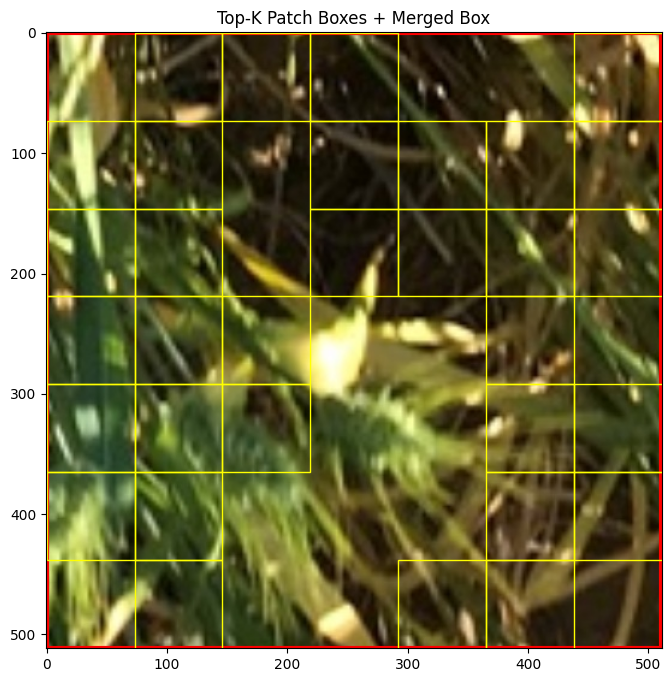

In [170]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(image)

rect = patches.Rectangle(

    (merged_box[0], merged_box[1]),

    merged_box[2]-merged_box[0],

    merged_box[3]-merged_box[1],

    linewidth=3,

    edgecolor="red",

    facecolor="none",

)

ax.add_patch(rect)

for b in boxes:

    rect = patches.Rectangle(

        (b[0], b[1]),

        b[2]-b[0],

        b[3]-b[1],

        linewidth=1,

        edgecolor="yellow",

        facecolor="none",

    )

    ax.add_patch(rect)

plt.title("Top-K Patch Boxes + Merged Box")

plt.show()

In [171]:
print("Merged Box:", merged_box)

print("Image size:", image.size)

print("GT foreground:", gt_mask.sum())

Merged Box: [  0   0 511 511]
Image size: (512, 512)
GT foreground: 208628


In [172]:
# ============================================================
# LOAD FINE-TUNED SAM2 MODEL
# Experiment E: Combined Augmentation
# ============================================================

import torch
from transformers import Sam2Processor, Sam2Model

sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

print("\nCheckpoint keys:")
if isinstance(sam2_checkpoint, dict):
    print(list(sam2_checkpoint.keys()))

# ------------------------------------------------------------
# Extract mask decoder weights
# ------------------------------------------------------------

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):

    mask_decoder_state_dict = (
        sam2_checkpoint["mask_decoder_state_dict"]
    )

else:
    raise TypeError(
        "E_Combined checkpoint does not contain "
        "'mask_decoder_state_dict'."
    )

# ------------------------------------------------------------
# Load decoder
# ------------------------------------------------------------

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("\n" + "=" * 70)
print("FINE-TUNED SAM2 LOADED")
print("=" * 70)
print("Experiment: E_Combined")
print("Checkpoint:", SAM2_CHECKPOINT)
print("Checkpoint epoch:", sam2_checkpoint.get("epoch"))
print(
    "Best IoU from training:",
    sam2_checkpoint.get("best_iou")
)
print("\nDecoder loading result:")
print(load_result)
print("=" * 70)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>

Checkpoint keys:
['experiment', 'augmentations', 'epoch', 'model_name', 'mask_decoder_state_dict', 'best_iou', 'history']

FINE-TUNED SAM2 LOADED
Experiment: E_Combined
Checkpoint: /home/zahranadeem/thesis/sam2_vegann_augmentation_checkpoints/E_Combined.pt
Checkpoint epoch: 8
Best IoU from training: 0.8802432

Decoder loading result:
<All keys matched successfully>


In [173]:
sam2_inputs = sam2_processor(

    images=image,

    input_boxes=[[merged_box]],
    #input_boxes = [[gt_box]],

    return_tensors="pt",

)

sam2_inputs = {

    k: v.to(device)

    if torch.is_tensor(v)

    else v

    for k, v in sam2_inputs.items()

}

with torch.no_grad():

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

print(sam2_outputs.pred_masks.shape)
print(sam2_outputs.iou_scores.shape)

torch.Size([1, 1, 3, 256, 256])
torch.Size([1, 1, 3])


In [174]:
# Pick best candidate

best_index = sam2_outputs.iou_scores[0,0].argmax()

print("Best candidate:", best_index.item())

# Raw logits

best_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_index
]

print(best_logits.shape)

# Convert to probability

best_mask_probability = torch.sigmoid(best_logits)

# Resize to original image size

best_mask_probability = torch.nn.functional.interpolate(

    best_mask_probability.unsqueeze(0).unsqueeze(0),

    size=gt_mask.shape,

    mode="bilinear",

    align_corners=False,

).squeeze()

best_mask = (

    best_mask_probability > 0.15

).cpu().numpy().astype(np.uint8)

print(best_mask.shape)

Best candidate: 2
torch.Size([256, 256])
(512, 512)


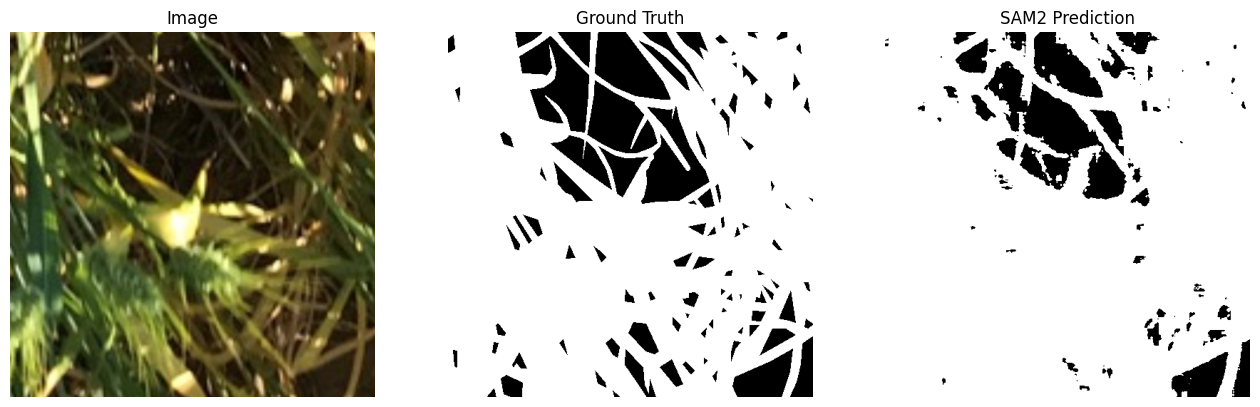

In [175]:
plt.figure(figsize=(16,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask,cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(133)
plt.imshow(best_mask,cmap="gray")
plt.title("SAM2 Prediction")
plt.axis("off")

plt.show()

In [176]:
#Select and decode the best SAM2 candidate 
best_candidate_index = int(
    sam2_outputs.iou_scores[0, 0]
    .argmax()
    .item()
)

best_mask_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_candidate_index,
]

best_mask_probability = torch.sigmoid(
    best_mask_logits
)

original_height = int(
    sam2_inputs["original_sizes"][0, 0].item()
)
original_width = int(
    sam2_inputs["original_sizes"][0, 1].item()
)

best_mask_probability = F.interpolate(
    best_mask_probability[None, None],
    size=(original_height, original_width),
    mode="bilinear",
    align_corners=False,
)[0, 0]

pred_mask = (
    best_mask_probability >= 0.5
).detach().cpu().numpy().astype(np.uint8)

print("Selected SAM2 candidate:", best_candidate_index)
print(
    "Predicted IoU confidence:",
    float(
        sam2_outputs.iou_scores[
            0,
            0,
            best_candidate_index,
        ].item()
    ),
)
print("Prediction shape:", pred_mask.shape)
print("Foreground pixels:", int(pred_mask.sum()))

Selected SAM2 candidate: 2
Predicted IoU confidence: 0.9720879793167114
Prediction shape: (512, 512)
Foreground pixels: 202055


Min : 0.00048319233
Max : 0.9998857
Mean: 0.75550145
Std : 0.34148532


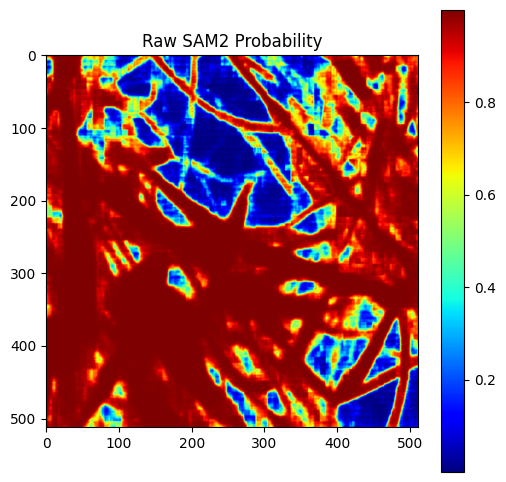

In [177]:
# Visualize raw SAM2 probability

prob = best_mask_probability.detach().cpu().numpy()

print("Min :", prob.min())
print("Max :", prob.max())
print("Mean:", prob.mean())
print("Std :", prob.std())

plt.figure(figsize=(6,6))
plt.imshow(prob, cmap="jet")
plt.colorbar()
plt.title("Raw SAM2 Probability")
plt.show()

In [178]:
#Define segmentation metrics 
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = pred_pixels + gt_pixels

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }


metrics = compute_binary_metrics(
    pred_mask,
    gt_mask,
)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name:>14}: {value:.4f}")
    else:
        print(f"{name:>14}: {value}")


           iou: 0.8856
          dice: 0.9393
     precision: 0.9546
        recall: 0.9245
  intersection: 192887
         union: 217796
   pred_pixels: 202055
     gt_pixels: 208628


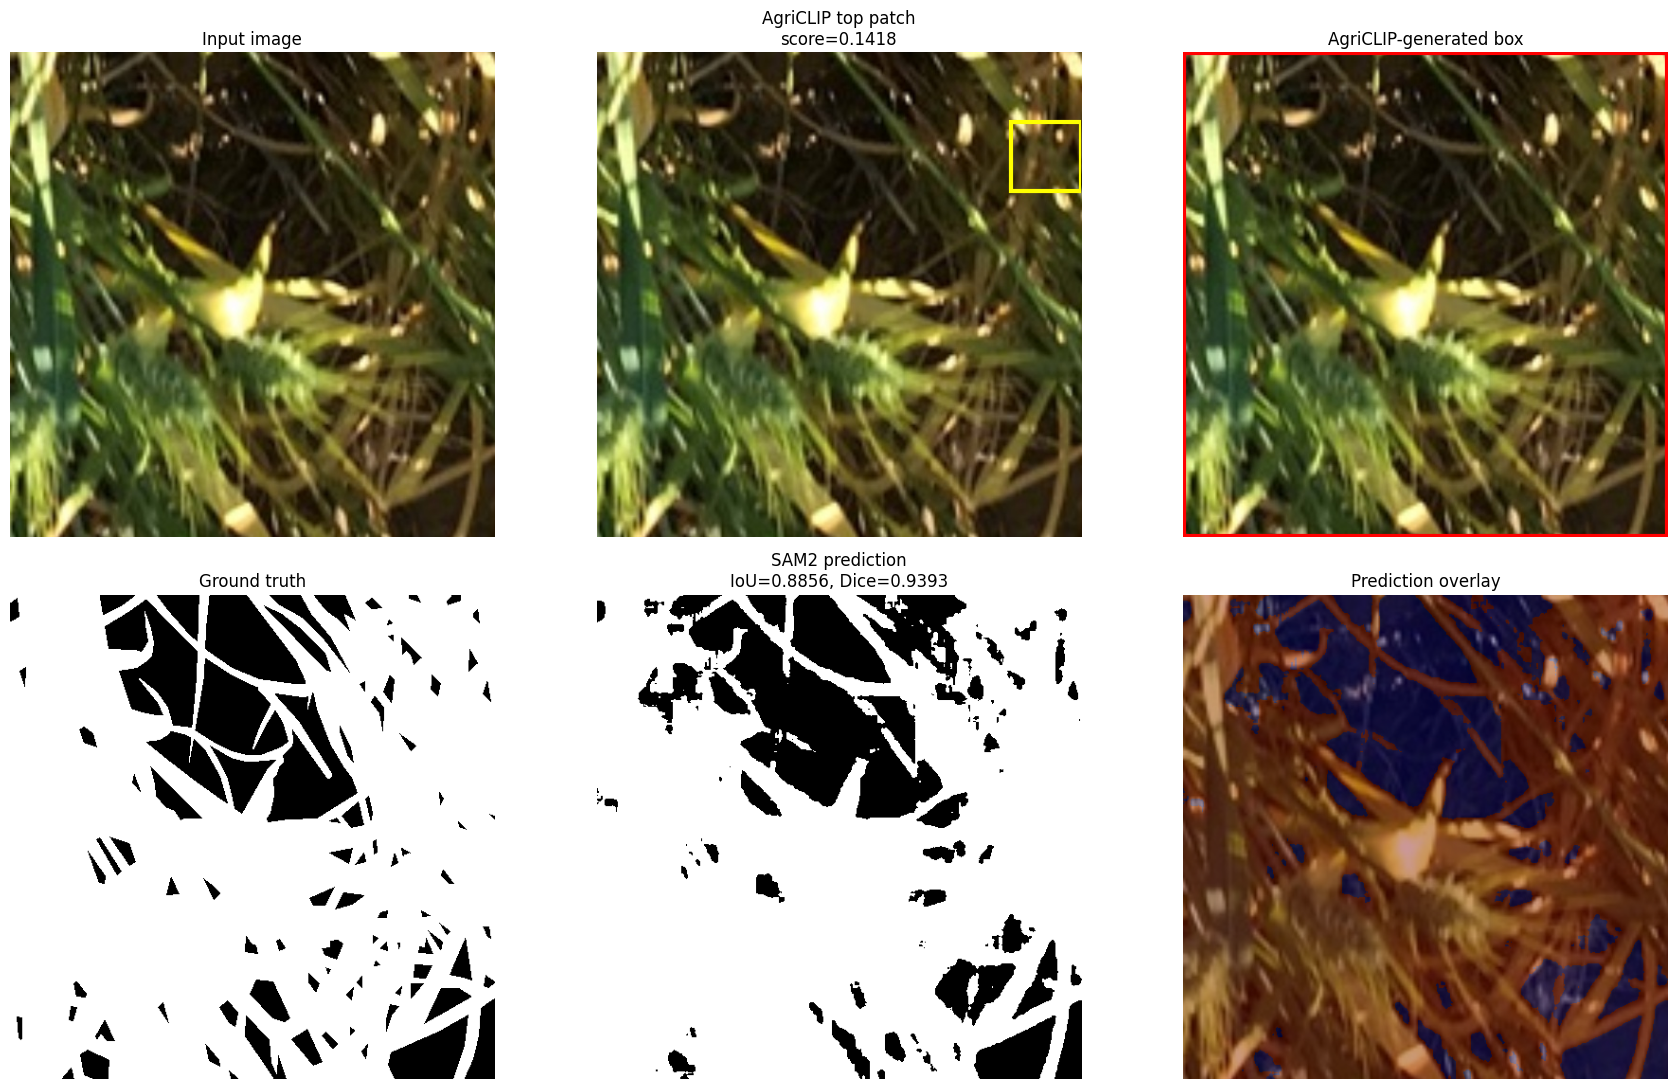

In [179]:
# Visualize the complete result

fig, ax = plt.subplots(
    2,
    3,
    figsize=(18, 11),
)

# Image
ax[0, 0].imshow(image)
ax[0, 0].set_title("Input image")
ax[0, 0].axis("off")



# Winning patch
best_patch = boxes[0]

ax[0, 1].imshow(image)

ax[0, 1].add_patch(
    plt.Rectangle(
        (best_patch[0], best_patch[1]),
        best_patch[2] - best_patch[0],
        best_patch[3] - best_patch[1],
        fill=False,
        edgecolor="yellow",
        linewidth=3,
    )
)

ax[0, 1].set_title(
    f"AgriCLIP top patch\nscore={scores[topk_indices[0]]:.4f}"
)

ax[0, 1].axis("off")


# Expanded AgriCLIP box
ax[0, 2].imshow(image)

ax[0, 2].add_patch(
    plt.Rectangle(
        (merged_box[0], merged_box[1]),
        merged_box[2] - merged_box[0],
        merged_box[3] - merged_box[1],
        fill=False,
        edgecolor="red",
        linewidth=3,
    )
)

ax[0, 2].set_title(
    "AgriCLIP-generated box"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray",
)

ax[1, 0].set_title(
    "Ground truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray",
)

ax[1, 1].set_title(
    f"SAM2 prediction\n"
    f"IoU={metrics['iou']:.4f}, "
    f"Dice={metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.40,
)

ax[1, 2].set_title(
    "Prediction overlay"
)

ax[1, 2].axis("off")


plt.tight_layout()
plt.show()

In [180]:
#generate the box
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k = 32

):

    # Extract DINO patches
    patch_features, grid_h, grid_w = extract_dino_patch_features(
        image
    )


    # Align to AgriCLIP space
    aligned_features = align_patch_features(
        patch_features
    )


    # Patch-text similarity
    patch_scores = (
        aligned_features 
        @ vegetation_embedding
    )


    scores = patch_scores.cpu().numpy()


    # Top-K patches
    topk_indices = np.argsort(scores)[::-1][:top_k]


    H, W = image.size[1], image.size[0]


    patch_h = H / grid_h
    patch_w = W / grid_w


    boxes = []


    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w


        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c+1) * patch_w)
        y2 = int((r+1) * patch_h)


        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.array(boxes)


    # Merge boxes
    xmin = boxes[:,0].min()
    ymin = boxes[:,1].min()

    xmax = boxes[:,2].max()
    ymax = boxes[:,3].max()


    margin = 25


    xmin = max(
        0,
        xmin-margin
    )

    ymin = max(
        0,
        ymin-margin
    )

    xmax = min(
        W-1,
        xmax+margin
    )

    ymax = min(
        H-1,
        ymax+margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )

In [181]:
# ============================================================
# SAM2 PREDICTION FUNCTION
# AgriCLIP Box -> Fine-tuned E_Combined SAM2
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np


@torch.no_grad()
def sam2_predict_box(image, box):

    # --------------------------------------------------------
    # Prepare SAM2 input
    # --------------------------------------------------------

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )

    # Move tensors to device
    inputs = {
        k: v.to(device) if torch.is_tensor(v) else v
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # SAM2 forward pass
    # --------------------------------------------------------

    outputs = sam2_model(
        **inputs
    )

    # --------------------------------------------------------
    # Check outputs
    # --------------------------------------------------------

    if not hasattr(outputs, "pred_masks"):
        raise RuntimeError(
            "SAM2 output does not contain pred_masks."
        )

    if not hasattr(outputs, "iou_scores"):
        raise RuntimeError(
            "SAM2 output does not contain iou_scores."
        )

    # --------------------------------------------------------
    # Select best mask candidate
    # --------------------------------------------------------

    iou_scores = outputs.iou_scores

    # Expected shape is typically:
    # [batch, prompts, num_masks]

    if iou_scores.ndim == 3:
        scores = iou_scores[0, 0]
    elif iou_scores.ndim == 2:
        scores = iou_scores[0]
    else:
        raise RuntimeError(
            f"Unexpected iou_scores shape: "
            f"{iou_scores.shape}"
        )

    best_idx = scores.argmax().item()

    confidence = scores[best_idx].item()

    # --------------------------------------------------------
    # Get corresponding mask logits
    # --------------------------------------------------------

    pred_masks = outputs.pred_masks

    # Expected:
    # [batch, prompts, num_masks, H, W]

    if pred_masks.ndim == 5:
        logits = pred_masks[
            0,
            0,
            best_idx
        ]

    elif pred_masks.ndim == 4:
        logits = pred_masks[
            0,
            best_idx
        ]

    else:
        raise RuntimeError(
            f"Unexpected pred_masks shape: "
            f"{pred_masks.shape}"
        )

    # --------------------------------------------------------
    # Convert logits -> probability
    # --------------------------------------------------------

    probability = torch.sigmoid(
        logits
    )

    # --------------------------------------------------------
    # Original image dimensions
    # --------------------------------------------------------

    original_sizes = inputs["original_sizes"]

    if torch.is_tensor(original_sizes):
        original_sizes = (
            original_sizes.detach()
            .cpu()
            .numpy()
        )

    original_sizes = np.asarray(
        original_sizes
    )

    # Usually [batch, 2]
    # where [height, width]

    height = int(
        original_sizes.reshape(-1, 2)[0, 0]
    )

    width = int(
        original_sizes.reshape(-1, 2)[0, 1]
    )

    # --------------------------------------------------------
    # Resize prediction to original image size
    # --------------------------------------------------------

    probability = F.interpolate(
        probability[None, None],
        size=(height, width),
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    # --------------------------------------------------------
    # Binary segmentation mask
    # --------------------------------------------------------

    prediction = (
        probability > 0.5
    ).cpu().numpy().astype(np.uint8)

    return prediction, confidence

In [182]:
import pandas as pd
from tqdm import tqdm

# Full validation loop
results = []
TOP_K = 32


for idx in tqdm(range(len(val_hf))):

    image = get_image(idx, split=val_hf)
    gt_mask = get_mask(idx, split=val_hf)

    try:
        # AgriCLIP localization
        agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
            image, TOP_K
        )

        # SAM2 segmentation
        pred_mask, confidence = sam2_predict_box(image, agriclip_box)

        # Metrics
        metrics = compute_binary_metrics(pred_mask, gt_mask)

        results.append(
            {
                "image_id": idx,
                "iou": metrics["iou"],
                "dice": metrics["dice"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "sam2_confidence": confidence,
            }
        )

    except Exception as e:
        print(f"Failed at image {idx}: {e}")
        raise e

print("\nFinished validation\n")

# ============================================================
# RESULTS AGGREGATION & PRINTING
# ============================================================
if len(results) > 0:
    results_df = pd.DataFrame(results)

    print("==================================================")
    print("           VALIDATION PERFORMANCE SUMMARY          ")
    print("==================================================")
    print(f"Total Evaluated Images:  {len(results_df)}")
    print(f"Mean Segmentation IoU:   {results_df['iou'].mean() * 100:.2f}%")
    print(f"Mean Dice Score:         {results_df['dice'].mean() * 100:.2f}%")
    print(f"Mean Precision:          {results_df['precision'].mean() * 100:.2f}%")
    print(f"Mean Recall:             {results_df['recall'].mean() * 100:.2f}%")
    print(f"Mean SAM2 Confidence:    {results_df['sam2_confidence'].mean():.4f}")
    print("==================================================")
else:
    print("No valid results computed.")


100%|██████████| 755/755 [00:32<00:00, 23.00it/s]


Finished validation

           VALIDATION PERFORMANCE SUMMARY          
Total Evaluated Images:  755
Mean Segmentation IoU:   84.45%
Mean Dice Score:         90.48%
Mean Precision:          89.77%
Mean Recall:             91.64%
Mean SAM2 Confidence:    0.9396


In [183]:
# ============================================================
# SAVE RESULT: AUGMENTED SAM2 + AGRICLIP
# Experiment E_Combined | K=32 | VegAnn Validation
# ============================================================

import pandas as pd
from pathlib import Path

augmented_sam2_agriclip_result = {
    "experiment": "Augmented SAM2 + AgriCLIP",
    "augmentation": "Rotation + Flipping",
    "sam2_checkpoint": "E_Combined.pt",
    "top_k": 32,
    "dataset": "VegAnn",
    "split": "Validation",
    "images": 755,
    "iou": 0.8445,
    "dice": 0.9048,
    "precision": 0.8977,
    "recall": 0.9164,
    "sam2_confidence": 0.9396
}

# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

augmented_sam2_agriclip_df = pd.DataFrame(
    [augmented_sam2_agriclip_result]
)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

RESULTS_DIR = (
    PROJECT_ROOT / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

save_path = (
    RESULTS_DIR
    / "augmented_sam2_agriclip_E_Combined_K32.csv"
)

augmented_sam2_agriclip_df.to_csv(
    save_path,
    index=False
)

# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("=" * 70)
print("RESULT SAVED")
print("=" * 70)

print(
    augmented_sam2_agriclip_df.to_string(
        index=False
    )
)

print("\nSaved to:")
print(save_path)

print("\n✓ Augmented SAM2 + AgriCLIP result saved successfully.")

RESULT SAVED
               experiment        augmentation sam2_checkpoint  top_k dataset      split  images    iou   dice  precision  recall  sam2_confidence
Augmented SAM2 + AgriCLIP Rotation + Flipping   E_Combined.pt     32  VegAnn Validation     755 0.8445 0.9048     0.8977  0.9164           0.9396

Saved to:
/home/zahranadeem/thesis/results/augmented_sam2_agriclip_E_Combined_K32.csv

✓ Augmented SAM2 + AgriCLIP result saved successfully.


## Debugging 

In [184]:
# ============================================================
# CELL 1: CHECK REQUIRED OBJECTS
# ============================================================

print("=" * 70)
print("CHECKING AGRICLIP + SAM2 PIPELINE")
print("=" * 70)

required_objects = [
    "sam2_processor",
    "sam2_model",
    "dino_model",
    "vegann_aligner",
    "vegetation_embedding",
    "val_hf",
    "get_image",
    "get_mask",
    "generate_agriclip_box",
    "compute_binary_metrics",
]

for name in required_objects:
    if name in globals():
        print(f"✓ {name}")
    else:
        print(f"✗ MISSING: {name}")

print("=" * 70)

print("\nSAM2 model:", type(sam2_model))
print("SAM2 processor:", type(sam2_processor))
print("Device:", device)

CHECKING AGRICLIP + SAM2 PIPELINE
✓ sam2_processor
✓ sam2_model
✓ dino_model
✓ vegann_aligner
✓ vegetation_embedding
✓ val_hf
✓ get_image
✓ get_mask
✓ generate_agriclip_box
✓ compute_binary_metrics

SAM2 model: <class 'transformers.models.sam2.modeling_sam2.Sam2Model'>
SAM2 processor: <class 'transformers.models.sam2.processing_sam2.Sam2Processor'>
Device: cuda


In [185]:
# ============================================================
# CELL 2: LOAD ONE VALIDATION IMAGE
# ============================================================

TEST_IDX = 0

image = get_image(TEST_IDX, split=val_hf)
gt_mask = get_mask(TEST_IDX, split=val_hf)

print("=" * 70)
print("TEST IMAGE")
print("=" * 70)

print("Image type:", type(image))
print("Image size:", image.size)

print("GT mask type:", type(gt_mask))
print("GT mask shape:", gt_mask.shape)
print("GT mask dtype:", gt_mask.dtype)

print("GT foreground pixels:", np.sum(gt_mask > 0))
print("GT foreground percentage:",
      100 * np.mean(gt_mask > 0))

print("=" * 70)

TEST IMAGE
Image type: <class 'PIL.Image.Image'>
Image size: (512, 512)
GT mask type: <class 'numpy.ndarray'>
GT mask shape: (512, 512)
GT mask dtype: uint8
GT foreground pixels: 208628
GT foreground percentage: 79.58526611328125


In [186]:
# ============================================================
# CELL 3: AGRICLIP BOX GENERATION
# ============================================================

TOP_K = 32

agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
    image,
    TOP_K
)

print("=" * 70)
print("AGRICLIP LOCALIZATION")
print("=" * 70)

print("K:", TOP_K)

print("\nAgriCLIP merged box:")
print(agriclip_box)

print("\nNumber of individual selected patches/boxes:",
      len(boxes))

print("\nTop-K indices:")
print(topk_indices)

print("\nScore range:")
print("Min:", np.min(scores))
print("Max:", np.max(scores))

print("=" * 70)

AGRICLIP LOCALIZATION
K: 32

AgriCLIP merged box:
[  0   0 511 511]

Number of individual selected patches/boxes: 32

Top-K indices:
[13 43  6 20 29 10  1 47 18  8 46 22 19  2  3 26 17 36 34 33 23 35 40 15
 30 12 21  7 14 41 11 28]

Score range:
Min: -0.020329272
Max: 0.14176683


In [187]:
# ============================================================
# CELL 4: COMPUTE GROUND-TRUTH BOUNDING BOX
# ============================================================

def mask_to_bbox(mask):
    ys, xs = np.where(mask > 0)

    if len(xs) == 0 or len(ys) == 0:
        return None

    x1 = xs.min()
    y1 = ys.min()
    x2 = xs.max()
    y2 = ys.max()

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.float32
    )


def bbox_iou(box_a, box_b):
    """
    Compute IoU between two boxes:
    [x1, y1, x2, y2]
    """

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)

    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    inter_w = max(0, inter_x2 - inter_x1)
    inter_h = max(0, inter_y2 - inter_y1)

    intersection = inter_w * inter_h

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    if union == 0:
        return 0.0

    return intersection / union


gt_box = mask_to_bbox(gt_mask)

print("=" * 70)
print("BOUNDING BOX COMPARISON")
print("=" * 70)

print("GT box:")
print(gt_box)

print("\nAgriCLIP box:")
print(agriclip_box)

box_iou = bbox_iou(
    agriclip_box,
    gt_box
)

print("\nBox IoU:")
print(f"{box_iou:.4f}")
print(f"{box_iou * 100:.2f}%")

print("=" * 70)

BOUNDING BOX COMPARISON
GT box:
[  0.   0. 511. 511.]

AgriCLIP box:
[  0   0 511 511]

Box IoU:
1.0000
100.00%


In [188]:
# ============================================================
# CELL 5: INSPECT SAM2 PROCESSOR
# ============================================================

print("=" * 70)
print("SAM2 PROCESSOR INSPECTION")
print("=" * 70)

print("Original image size:")
print(image.size)

print("\nInput box:")
print(agriclip_box)

sam2_inputs = sam2_processor(
    images=image,
    input_boxes=[
        [
            agriclip_box.tolist()
        ]
    ],
    return_tensors="pt"
)

print("\nProcessor outputs:")
for key, value in sam2_inputs.items():

    if torch.is_tensor(value):
        print(
            f"{key}: "
            f"shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
    else:
        print(
            f"{key}: "
            f"type={type(value)}, "
            f"value={value}"
        )

print("=" * 70)

SAM2 PROCESSOR INSPECTION
Original image size:
(512, 512)

Input box:
[  0   0 511 511]

Processor outputs:
pixel_values: shape=(1, 3, 1024, 1024), dtype=torch.float32
original_sizes: shape=(1, 2), dtype=torch.int64
input_boxes: shape=(1, 1, 4), dtype=torch.float32


In [189]:
# ============================================================
# CELL 6: INSPECT PROCESSED BOX
# ============================================================

print("=" * 70)
print("PROCESSED SAM2 BOX")
print("=" * 70)

if "input_boxes" in sam2_inputs:
    print(
        "input_boxes shape:",
        sam2_inputs["input_boxes"].shape
    )

    print(
        "input_boxes:",
        sam2_inputs["input_boxes"]
    )

if "original_sizes" in sam2_inputs:
    print(
        "\noriginal_sizes:",
        sam2_inputs["original_sizes"]
    )

if "reshaped_input_sizes" in sam2_inputs:
    print(
        "\nreshaped_input_sizes:",
        sam2_inputs["reshaped_input_sizes"]
    )

print("=" * 70)

PROCESSED SAM2 BOX
input_boxes shape: torch.Size([1, 1, 4])
input_boxes: tensor([[[   0.,    0., 1022., 1022.]]])

original_sizes: tensor([[512, 512]])


In [190]:
# ============================================================
# CELL 7: RAW SAM2 FORWARD PASS
# ============================================================

model_inputs = {
    k: v.to(device) if torch.is_tensor(v) else v
    for k, v in sam2_inputs.items()
}

with torch.no_grad():

    outputs = sam2_model(
        **model_inputs
    )

print("=" * 70)
print("RAW SAM2 OUTPUT")
print("=" * 70)

print("Output type:")
print(type(outputs))

print("\nAvailable output fields:")

if hasattr(outputs, "keys"):
    print(outputs.keys())

print("\n--- pred_masks ---")

if hasattr(outputs, "pred_masks"):
    print(
        "Shape:",
        outputs.pred_masks.shape
    )

    print(
        "Min:",
        outputs.pred_masks.min().item()
    )

    print(
        "Max:",
        outputs.pred_masks.max().item()
    )
else:
    print("pred_masks NOT FOUND")

print("\n--- iou_scores ---")

if hasattr(outputs, "iou_scores"):
    print(
        "Shape:",
        outputs.iou_scores.shape
    )

    print(
        "Values:",
        outputs.iou_scores
    )
else:
    print("iou_scores NOT FOUND")

print("=" * 70)

RAW SAM2 OUTPUT
Output type:
<class 'transformers.models.sam2.modeling_sam2.Sam2ImageSegmentationOutput'>

Available output fields:
odict_keys(['iou_scores', 'pred_masks', 'object_score_logits', 'image_embeddings'])

--- pred_masks ---
Shape: torch.Size([1, 1, 3, 256, 256])
Min: -8.138724327087402
Max: 9.338789939880371

--- iou_scores ---
Shape: torch.Size([1, 1, 3])
Values: tensor([[[0.9134, 0.7244, 0.9721]]], device='cuda:0')


In [191]:
# ============================================================
# CELL 8: INSPECT ALL SAM2 MASK CANDIDATES
# ============================================================

print("=" * 70)
print("SAM2 MASK CANDIDATES")
print("=" * 70)

pred_masks = outputs.pred_masks
iou_scores = outputs.iou_scores

print("pred_masks shape:", pred_masks.shape)
print("iou_scores shape:", iou_scores.shape)

# Flatten candidate dimension safely
scores_flat = iou_scores.detach().cpu().flatten()

print("\nNumber of IoU candidates:", len(scores_flat))

for i, score in enumerate(scores_flat):
    print(
        f"Candidate {i}: "
        f"SAM2 predicted IoU = {score.item():.4f}"
    )

print("=" * 70)

SAM2 MASK CANDIDATES
pred_masks shape: torch.Size([1, 1, 3, 256, 256])
iou_scores shape: torch.Size([1, 1, 3])

Number of IoU candidates: 3
Candidate 0: SAM2 predicted IoU = 0.9134
Candidate 1: SAM2 predicted IoU = 0.7244
Candidate 2: SAM2 predicted IoU = 0.9721


In [192]:
# ============================================================
# CELL 9: EXTRACT SAM2 CANDIDATE MASKS
# ============================================================

def extract_sam2_candidates(outputs):

    pred_masks = outputs.pred_masks
    iou_scores = outputs.iou_scores

    print("Original pred_masks shape:",
          tuple(pred_masks.shape))

    print("Original iou_scores shape:",
          tuple(iou_scores.shape))

    # Remove dimensions of size 1
    masks = pred_masks.squeeze()
    scores = iou_scores.squeeze()

    print("\nAfter squeeze:")
    print("Masks shape:", tuple(masks.shape))
    print("Scores shape:", tuple(scores.shape))

    # We expect:
    # masks = [N, H, W]
    # scores = [N]

    if masks.ndim == 2:
        masks = masks.unsqueeze(0)

    if scores.ndim == 0:
        scores = scores.unsqueeze(0)

    if masks.ndim != 3:
        raise RuntimeError(
            f"Unexpected mask shape after squeeze: "
            f"{masks.shape}"
        )

    if scores.ndim != 1:
        raise RuntimeError(
            f"Unexpected score shape after squeeze: "
            f"{scores.shape}"
        )

    if masks.shape[0] != scores.shape[0]:
        raise RuntimeError(
            f"Mask candidates ({masks.shape[0]}) "
            f"do not match scores ({scores.shape[0]})"
        )

    return masks, scores


candidate_masks, candidate_scores = (
    extract_sam2_candidates(outputs)
)

print("\nFinal candidate masks:",
      candidate_masks.shape)

print("Final candidate scores:",
      candidate_scores.shape)

print("=" * 70)

Original pred_masks shape: (1, 1, 3, 256, 256)
Original iou_scores shape: (1, 1, 3)

After squeeze:
Masks shape: (3, 256, 256)
Scores shape: (3,)

Final candidate masks: torch.Size([3, 256, 256])
Final candidate scores: torch.Size([3])


In [193]:
# ============================================================
# CELL 10: RESIZE SAM2 CANDIDATE MASKS
# ============================================================

original_height = int(
    sam2_inputs["original_sizes"][0, 0].item()
)

original_width = int(
    sam2_inputs["original_sizes"][0, 1].item()
)

print("=" * 70)
print("RESIZING SAM2 MASKS")
print("=" * 70)

print("Original image size:",
      original_width,
      "x",
      original_height)

candidate_probabilities = F.interpolate(
    candidate_masks.float().unsqueeze(1),
    size=(
        original_height,
        original_width
    ),
    mode="bilinear",
    align_corners=False
).squeeze(1)

print("Resized masks:",
      candidate_probabilities.shape)

print("=" * 70)

RESIZING SAM2 MASKS
Original image size: 512 x 512
Resized masks: torch.Size([3, 512, 512])


In [194]:
# ============================================================
# CELL 11: TEST ALL MASK CANDIDATES + THRESHOLDS
# ============================================================

thresholds = [
    -1.0,
    -0.5,
    0.0,
    0.25,
    0.5,
    0.75,
    1.0
]

print("=" * 70)
print("SAM2 CANDIDATE / THRESHOLD ANALYSIS")
print("=" * 70)

diagnostic_results = []

for candidate_idx in range(
    candidate_probabilities.shape[0]
):

    logits = candidate_probabilities[
        candidate_idx
    ]

    # NOTE:
    # These are logits if pred_masks are logits.
    # We test sigmoid probabilities below.

    probabilities = torch.sigmoid(
        logits
    )

    for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

        pred = (
            probabilities > threshold
        ).cpu().numpy().astype(np.uint8)

        metrics = compute_binary_metrics(
            pred,
            gt_mask
        )

        diagnostic_results.append(
            {
                "candidate": candidate_idx,
                "sam2_score": float(
                    candidate_scores[
                        candidate_idx
                    ].item()
                ),
                "threshold": threshold,
                "iou": metrics["iou"],
                "dice": metrics["dice"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "pred_area": int(pred.sum())
            }
        )

diagnostic_df = pd.DataFrame(
    diagnostic_results
)

print(
    diagnostic_df.sort_values(
        "iou",
        ascending=False
    ).to_string(index=False)
)

print("=" * 70)

SAM2 CANDIDATE / THRESHOLD ANALYSIS
 candidate  sam2_score  threshold      iou     dice  precision   recall  pred_area
         0    0.913362        0.5 0.912195 0.954082   0.940051 0.968537     214950
         0    0.913362        0.4 0.907635 0.951581   0.920090 0.985304     223415
         1    0.724369        0.3 0.907337 0.951417   0.945867 0.957034     211091
         0    0.913362        0.6 0.901376 0.948130   0.957423 0.939016     204617
         2    0.972088        0.3 0.899866 0.947294   0.931911 0.963193     215631
         2    0.972088        0.4 0.894981 0.944580   0.944383 0.944777     208715
         1    0.724369        0.4 0.892819 0.943375   0.962406 0.925082     200537
         0    0.913362        0.3 0.887931 0.940639   0.892126 0.994732     232623
         2    0.972088        0.5 0.885824 0.939456   0.954717 0.924675     202063
         0    0.913362        0.7 0.873798 0.932649   0.973373 0.895196     191872
         2    0.972088        0.6 0.872630 0.931983

In [195]:
# ============================================================
# CELL 12: GT BOX VS AGRICLIP BOX
# ============================================================

def run_raw_sam2_box(image, box):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in inputs.items()
    }

    with torch.no_grad():
        outputs = sam2_model(
            **inputs
        )

    masks, scores = extract_sam2_candidates(
        outputs
    )

    original_h = int(
        inputs["original_sizes"][0, 0].item()
    )

    original_w = int(
        inputs["original_sizes"][0, 1].item()
    )

    masks = F.interpolate(
        masks.float().unsqueeze(1),
        size=(original_h, original_w),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    return (
        masks.cpu(),
        scores.cpu()
    )


print("=" * 70)
print("GT BOX VS AGRICLIP BOX")
print("=" * 70)

# GT box
gt_masks, gt_scores = run_raw_sam2_box(
    image,
    gt_box
)

# AgriCLIP box
agriclip_masks, agriclip_scores = (
    run_raw_sam2_box(
        image,
        agriclip_box
    )
)

print("\nGT-box SAM2 scores:")
print(gt_scores)

print("\nAgriCLIP-box SAM2 scores:")
print(agriclip_scores)

print("=" * 70)

GT BOX VS AGRICLIP BOX
Original pred_masks shape: (1, 1, 3, 256, 256)
Original iou_scores shape: (1, 1, 3)

After squeeze:
Masks shape: (3, 256, 256)
Scores shape: (3,)
Original pred_masks shape: (1, 1, 3, 256, 256)
Original iou_scores shape: (1, 1, 3)

After squeeze:
Masks shape: (3, 256, 256)
Scores shape: (3,)

GT-box SAM2 scores:
tensor([0.9134, 0.7244, 0.9721])

AgriCLIP-box SAM2 scores:
tensor([0.9134, 0.7244, 0.9721])


In [196]:
# ============================================================
# CELL 13: GT BOX VS AGRICLIP BOX PERFORMANCE
# ============================================================

def evaluate_candidates(
    masks,
    scores,
    gt_mask,
    threshold=0.5
):

    rows = []

    for i in range(masks.shape[0]):

        probabilities = torch.sigmoid(
            masks[i]
        )

        prediction = (
            probabilities > threshold
        ).numpy().astype(np.uint8)

        metrics = compute_binary_metrics(
            prediction,
            gt_mask
        )

        rows.append(
            {
                "candidate": i,
                "sam2_confidence": float(
                    scores[i].item()
                ),
                "iou": metrics["iou"],
                "dice": metrics["dice"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "area": int(
                    prediction.sum()
                )
            }
        )

    return pd.DataFrame(rows)


gt_box_results = evaluate_candidates(
    gt_masks,
    gt_scores,
    gt_mask
)

agriclip_box_results = evaluate_candidates(
    agriclip_masks,
    agriclip_scores,
    gt_mask
)

print("=" * 70)
print("GT BOX → SAM2")
print("=" * 70)

print(
    gt_box_results.to_string(index=False)
)

print("\n")
print("=" * 70)
print("AGRICLIP BOX → SAM2")
print("=" * 70)

print(
    agriclip_box_results.to_string(index=False)
)

print("=" * 70)

GT BOX → SAM2
 candidate  sam2_confidence      iou     dice  precision   recall   area
         0         0.913362 0.912195 0.954082   0.940051 0.968537 214950
         1         0.724369 0.863014 0.926471   0.975400 0.882216 188697
         2         0.972088 0.885824 0.939456   0.954717 0.924675 202063


AGRICLIP BOX → SAM2
 candidate  sam2_confidence      iou     dice  precision   recall   area
         0         0.913362 0.912195 0.954082   0.940051 0.968537 214950
         1         0.724369 0.863014 0.926471   0.975400 0.882216 188697
         2         0.972088 0.885824 0.939456   0.954717 0.924675 202063


In [197]:
# ============================================================
# CELL 14: DIRECT COMPARISON
# ============================================================

best_gt = gt_box_results.loc[
    gt_box_results["iou"].idxmax()
]

best_agriclip = agriclip_box_results.loc[
    agriclip_box_results["iou"].idxmax()
]

print("=" * 70)
print("DIRECT SAM2 COMPARISON")
print("=" * 70)

print("\nGT BOX:")
print(
    f"Best candidate: {int(best_gt['candidate'])}"
)
print(
    f"SAM2 confidence: "
    f"{best_gt['sam2_confidence']:.4f}"
)
print(
    f"IoU: "
    f"{100 * best_gt['iou']:.2f}%"
)
print(
    f"Dice: "
    f"{100 * best_gt['dice']:.2f}%"
)

print("\nAGRICLIP BOX:")
print(
    f"Best candidate: "
    f"{int(best_agriclip['candidate'])}"
)
print(
    f"SAM2 confidence: "
    f"{best_agriclip['sam2_confidence']:.4f}"
)
print(
    f"IoU: "
    f"{100 * best_agriclip['iou']:.2f}%"
)
print(
    f"Dice: "
    f"{100 * best_agriclip['dice']:.2f}%"
)

print("\nBOX IoU:")
print(
    f"{100 * box_iou:.2f}%"
)

print("=" * 70)

DIRECT SAM2 COMPARISON

GT BOX:
Best candidate: 0
SAM2 confidence: 0.9134
IoU: 91.22%
Dice: 95.41%

AGRICLIP BOX:
Best candidate: 0
SAM2 confidence: 0.9134
IoU: 91.22%
Dice: 95.41%

BOX IoU:
100.00%


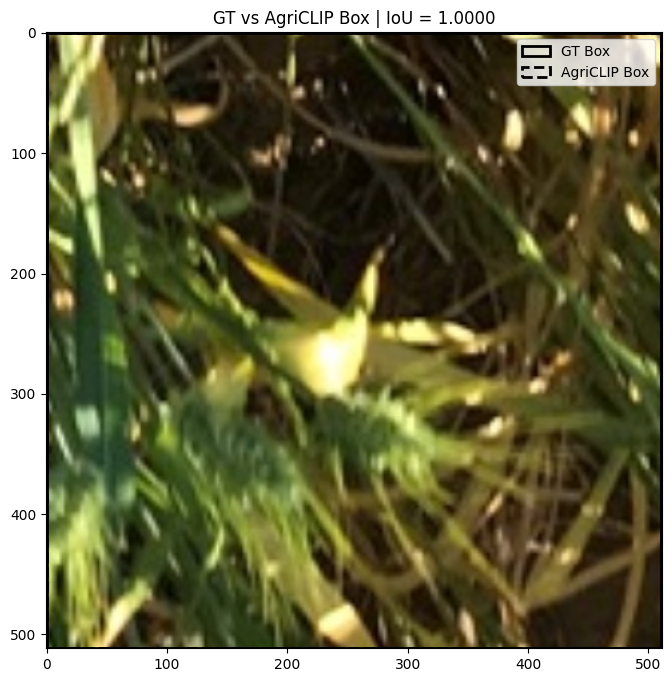

In [198]:
# ============================================================
# CELL 15: VISUALIZE GT + AGRICLIP BOX
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

# GT box
gx1, gy1, gx2, gy2 = gt_box

gt_rect = patches.Rectangle(
    (gx1, gy1),
    gx2 - gx1,
    gy2 - gy1,
    fill=False,
    linewidth=2,
    label="GT Box"
)

ax.add_patch(gt_rect)

# AgriCLIP box
ax1, ay1, ax2, ay2 = agriclip_box

agri_rect = patches.Rectangle(
    (ax1, ay1),
    ax2 - ax1,
    ay2 - ay1,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="AgriCLIP Box"
)

ax.add_patch(agri_rect)

ax.set_title(
    f"GT vs AgriCLIP Box | IoU = {box_iou:.4f}"
)

ax.legend()

plt.show()

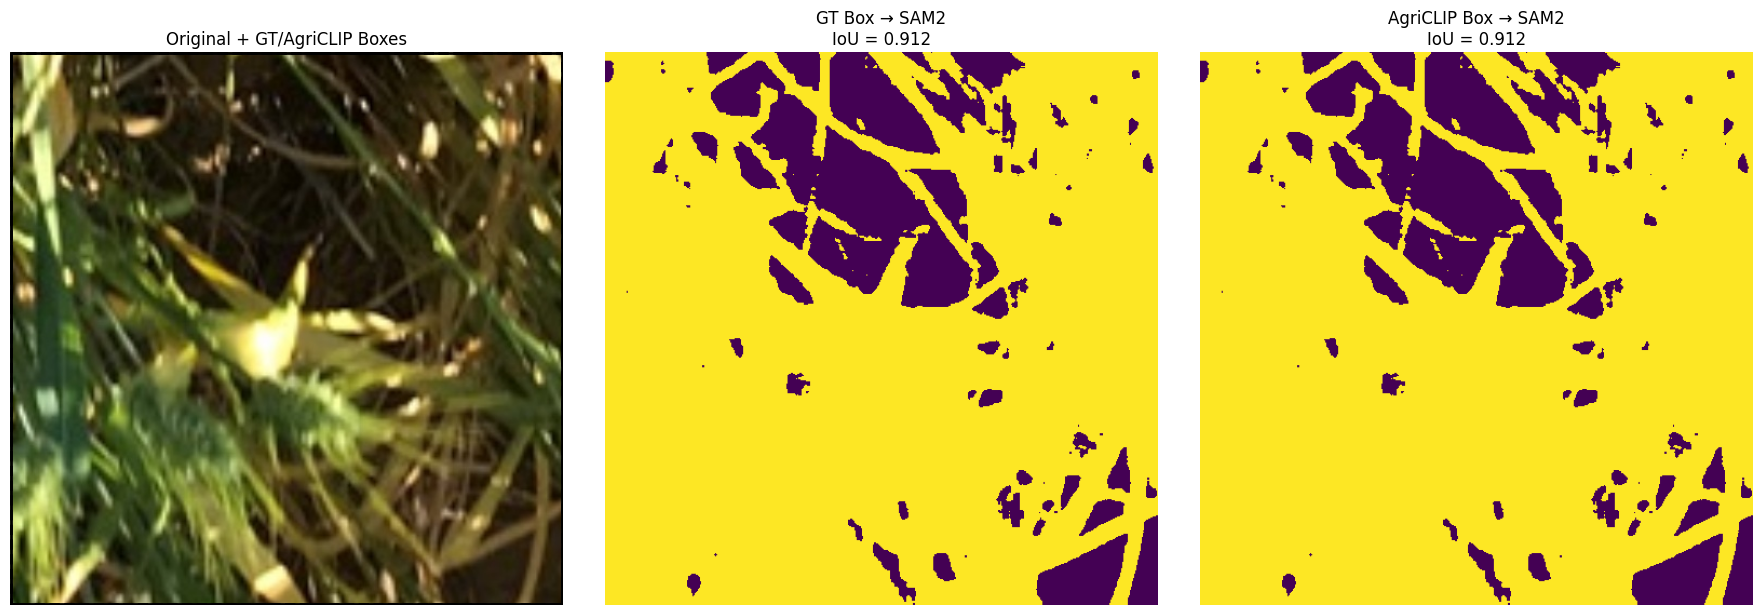

In [199]:
# ============================================================
# CELL 16: VISUALIZE SAM2 PREDICTIONS
# ============================================================

best_gt_idx = int(
    best_gt["candidate"]
)

best_agri_idx = int(
    best_agriclip["candidate"]
)

gt_prediction = (
    torch.sigmoid(
        gt_masks[best_gt_idx]
    ) > 0.5
).numpy().astype(np.uint8)

agri_prediction = (
    torch.sigmoid(
        agriclip_masks[best_agri_idx]
    ) > 0.5
).numpy().astype(np.uint8)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

# Original
axes[0].imshow(image)
axes[0].set_title("Original + GT/AgriCLIP Boxes")
axes[0].axis("off")

gx1, gy1, gx2, gy2 = gt_box
axes[0].add_patch(
    patches.Rectangle(
        (gx1, gy1),
        gx2 - gx1,
        gy2 - gy1,
        fill=False,
        linewidth=2
    )
)

ax1, ay1, ax2, ay2 = agriclip_box
axes[0].add_patch(
    patches.Rectangle(
        (ax1, ay1),
        ax2 - ax1,
        ay2 - ay1,
        fill=False,
        linewidth=2,
        linestyle="--"
    )
)

# GT box → SAM2
axes[1].imshow(gt_prediction)
axes[1].set_title(
    f"GT Box → SAM2\n"
    f"IoU = {best_gt['iou']:.3f}"
)
axes[1].axis("off")

# AgriCLIP box → SAM2
axes[2].imshow(agri_prediction)
axes[2].set_title(
    f"AgriCLIP Box → SAM2\n"
    f"IoU = {best_agriclip['iou']:.3f}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

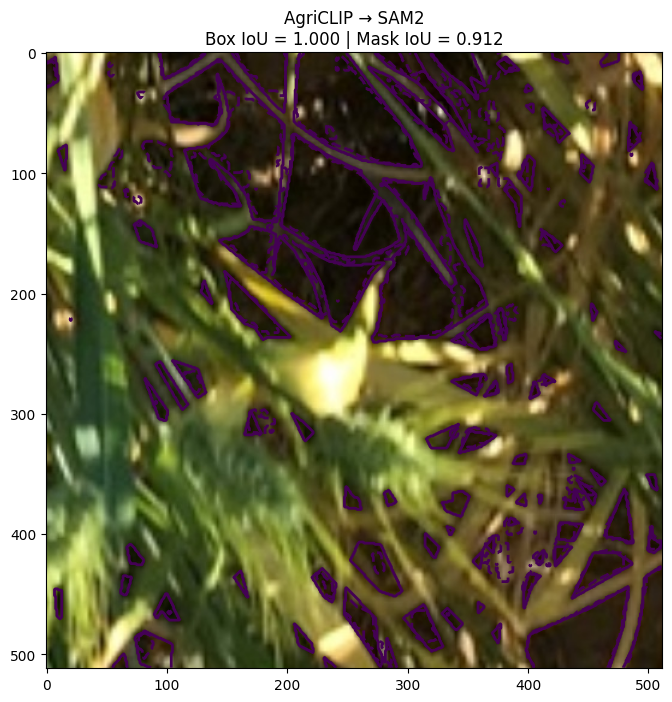

In [200]:
# ============================================================
# CELL 17: OVERLAY AGRICLIP-SAM2 WITH GT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

# GT contour
ax.contour(
    gt_mask,
    levels=[0.5],
    linewidths=2
)

# AgriCLIP-SAM2 contour
ax.contour(
    agri_prediction,
    levels=[0.5],
    linewidths=2,
    linestyles="--"
)

ax.set_title(
    f"AgriCLIP → SAM2\n"
    f"Box IoU = {box_iou:.3f} | "
    f"Mask IoU = {best_agriclip['iou']:.3f}"
)

plt.show()

In [201]:
# ============================================================
# CELL 18: TEST EXISTING SAM2 PREDICTION FUNCTION
# ============================================================

print("=" * 70)
print("TESTING EXISTING sam2_predict_box()")
print("=" * 70)

existing_prediction, existing_confidence = (
    sam2_predict_box(
        image,
        agriclip_box
    )
)

existing_metrics = compute_binary_metrics(
    existing_prediction,
    gt_mask
)

print(
    "Existing function confidence:",
    existing_confidence
)

print(
    "Existing function IoU:",
    existing_metrics["iou"]
)

print(
    "Existing function Dice:",
    existing_metrics["dice"]
)

print(
    "Existing function Precision:",
    existing_metrics["precision"]
)

print(
    "Existing function Recall:",
    existing_metrics["recall"]
)

print("=" * 70)

TESTING EXISTING sam2_predict_box()
Existing function confidence: 0.9720879793167114
Existing function IoU: 0.8856315083839924
Existing function Dice: 0.939347379852587
Existing function Precision: 0.954626215634357
Existing function Recall: 0.9245499165979638


In [202]:
# ============================================================
# FULL 755-IMAGE CANDIDATE ANALYSIS
#
# Question:
# Does SAM2 choose the wrong mask candidate?
#
# AgriCLIP K=32 -> AgriCLIP Box -> E_Combined SAM2
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

print("=" * 70)
print("SAM2 3-CANDIDATE ANALYSIS")
print("=" * 70)

print("Images:", len(val_hf))
print("TOP_K:", 32)

# ------------------------------------------------------------
# Make sure model is evaluation mode
# ------------------------------------------------------------

sam2_model.eval()

print("✓ SAM2 in evaluation mode")


# ============================================================
# FUNCTION: GET ALL SAM2 MASK CANDIDATES
# ============================================================

@torch.no_grad()
def sam2_predict_all_candidates(image, box):

    # --------------------------------------------------------
    # Prepare SAM2 input
    # --------------------------------------------------------

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # SAM2 forward
    # --------------------------------------------------------

    outputs = sam2_model(**inputs)

    # --------------------------------------------------------
    # Get outputs
    # --------------------------------------------------------

    logits = outputs.pred_masks

    scores = outputs.iou_scores

    # Expected:
    #
    # pred_masks:
    # [1, 1, 3, 256, 256]
    #
    # scores:
    # [1, 1, 3]
    # --------------------------------------------------------

    logits = logits[0, 0]

    scores = scores[0, 0]

    # --------------------------------------------------------
    # Convert logits to probabilities
    # --------------------------------------------------------

    probabilities = torch.sigmoid(logits)

    # --------------------------------------------------------
    # Resize all masks to original image size
    # --------------------------------------------------------

    height = int(
        inputs["original_sizes"][0, 0].item()
    )

    width = int(
        inputs["original_sizes"][0, 1].item()
    )

    probabilities = F.interpolate(
        probabilities.unsqueeze(1),
        size=(height, width),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    # --------------------------------------------------------
    # Threshold
    # --------------------------------------------------------

    masks = (
        probabilities > 0.5
    ).cpu().numpy().astype(np.uint8)

    return masks, scores.cpu().numpy()


# ============================================================
# METRIC FUNCTION
# ============================================================

def compute_metrics_numpy(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    union = np.logical_or(
        pred,
        gt
    ).sum()

    pred_area = pred.sum()
    gt_area = gt.sum()

    # IoU
    if union == 0:
        iou = 1.0 if pred_area == 0 else 0.0
    else:
        iou = intersection / union

    # Dice
    denominator = pred_area + gt_area

    if denominator == 0:
        dice = 1.0
    else:
        dice = (
            2.0 * intersection
            / denominator
        )

    # Precision
    fp = np.logical_and(
        pred,
        ~gt
    ).sum()

    precision_den = intersection + fp

    if precision_den == 0:
        precision = 1.0
    else:
        precision = intersection / precision_den

    # Recall
    fn = np.logical_and(
        ~pred,
        gt
    ).sum()

    recall_den = intersection + fn

    if recall_den == 0:
        recall = 1.0
    else:
        recall = intersection / recall_den

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall)
    }


# ============================================================
# FULL ANALYSIS
# ============================================================

candidate_results = []

print("\nStarting 755-image analysis...\n")

for idx in tqdm(
    range(len(val_hf)),
    desc="Analyzing SAM2 candidates"
):

    try:

        # ----------------------------------------------------
        # Load image + GT
        # ----------------------------------------------------

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # AgriCLIP localization
        # ----------------------------------------------------

        agriclip_box, boxes, scores, topk_indices = (
            generate_agriclip_box(
                image,
                32
            )
        )

        # ----------------------------------------------------
        # Get ALL 3 SAM2 candidates
        # ----------------------------------------------------

        masks, sam_scores = (
            sam2_predict_all_candidates(
                image,
                agriclip_box
            )
        )

        # ----------------------------------------------------
        # Calculate actual IoU for each candidate
        # ----------------------------------------------------

        candidate_metrics = []

        for candidate_idx in range(
            len(masks)
        ):

            metrics = compute_metrics_numpy(
                masks[candidate_idx],
                gt_mask
            )

            candidate_metrics.append(
                metrics
            )

        # ----------------------------------------------------
        # Candidate selected by SAM2 confidence
        # ----------------------------------------------------

        selected_idx = int(
            np.argmax(sam_scores)
        )

        # ----------------------------------------------------
        # Oracle candidate
        #
        # This is ONLY for diagnosis.
        # It uses GT to find the best candidate.
        # DO NOT report this as final model performance.
        # ----------------------------------------------------

        oracle_idx = int(
            np.argmax([
                x["iou"]
                for x in candidate_metrics
            ])
        )

        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        row = {
            "image_id": idx,

            # SAM2 confidence
            "candidate0_conf": float(
                sam_scores[0]
            ),
            "candidate1_conf": float(
                sam_scores[1]
            ),
            "candidate2_conf": float(
                sam_scores[2]
            ),

            # Actual IoU
            "candidate0_iou":
                candidate_metrics[0]["iou"],

            "candidate1_iou":
                candidate_metrics[1]["iou"],

            "candidate2_iou":
                candidate_metrics[2]["iou"],

            # Actual Dice
            "candidate0_dice":
                candidate_metrics[0]["dice"],

            "candidate1_dice":
                candidate_metrics[1]["dice"],

            "candidate2_dice":
                candidate_metrics[2]["dice"],

            # SAM2 selected candidate
            "selected_candidate":
                selected_idx,

            "selected_iou":
                candidate_metrics[
                    selected_idx
                ]["iou"],

            "selected_dice":
                candidate_metrics[
                    selected_idx
                ]["dice"],

            # Oracle
            "oracle_candidate":
                oracle_idx,

            "oracle_iou":
                candidate_metrics[
                    oracle_idx
                ]["iou"],

            "oracle_dice":
                candidate_metrics[
                    oracle_idx
                ]["dice"],
        }

        candidate_results.append(row)

    except Exception as e:

        print(
            f"\nERROR on image {idx}: "
            f"{type(e).__name__}: {e}"
        )

        raise e


# ============================================================
# DATAFRAME
# ============================================================

candidate_df = pd.DataFrame(
    candidate_results
)

print("\n" + "=" * 70)
print("CANDIDATE ANALYSIS FINISHED")
print("=" * 70)

print(
    "Images successfully analyzed:",
    len(candidate_df)
)

SAM2 3-CANDIDATE ANALYSIS
Images: 755
TOP_K: 32
✓ SAM2 in evaluation mode

Starting 755-image analysis...



Analyzing SAM2 candidates:   0%|          | 0/755 [00:00<?, ?it/s]


CANDIDATE ANALYSIS FINISHED
Images successfully analyzed: 755


In [203]:
# ============================================================
# COMPARE SAM2 CANDIDATE STRATEGIES
# ============================================================

print("=" * 70)
print("SAM2 CANDIDATE STRATEGY COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# Candidate 0
# ------------------------------------------------------------

candidate0_iou = (
    candidate_df["candidate0_iou"].mean()
)

candidate0_dice = (
    candidate_df["candidate0_dice"].mean()
)

# ------------------------------------------------------------
# Candidate 1
# ------------------------------------------------------------

candidate1_iou = (
    candidate_df["candidate1_iou"].mean()
)

candidate1_dice = (
    candidate_df["candidate1_dice"].mean()
)

# ------------------------------------------------------------
# Candidate 2
# ------------------------------------------------------------

candidate2_iou = (
    candidate_df["candidate2_iou"].mean()
)

candidate2_dice = (
    candidate_df["candidate2_dice"].mean()
)

# ------------------------------------------------------------
# SAM2 confidence-selected candidate
# ------------------------------------------------------------

selected_iou = (
    candidate_df["selected_iou"].mean()
)

selected_dice = (
    candidate_df["selected_dice"].mean()
)

# ------------------------------------------------------------
# Oracle
# ------------------------------------------------------------

oracle_iou = (
    candidate_df["oracle_iou"].mean()
)

oracle_dice = (
    candidate_df["oracle_dice"].mean()
)

# ============================================================
# PRINT
# ============================================================

print()

print(
    f"Candidate 0 IoU:        {candidate0_iou*100:.2f}%"
)

print(
    f"Candidate 0 Dice:       {candidate0_dice*100:.2f}%"
)

print()

print(
    f"Candidate 1 IoU:        {candidate1_iou*100:.2f}%"
)

print(
    f"Candidate 1 Dice:       {candidate1_dice*100:.2f}%"
)

print()

print(
    f"Candidate 2 IoU:        {candidate2_iou*100:.2f}%"
)

print(
    f"Candidate 2 Dice:       {candidate2_dice*100:.2f}%"
)

print()

print(
    f"SAM2 confidence IoU:    {selected_iou*100:.2f}%"
)

print(
    f"SAM2 confidence Dice:   {selected_dice*100:.2f}%"
)

print()

print(
    f"Oracle best-candidate IoU:  "
    f"{oracle_iou*100:.2f}%"
)

print(
    f"Oracle best-candidate Dice: "
    f"{oracle_dice*100:.2f}%"
)

print("=" * 70)

SAM2 CANDIDATE STRATEGY COMPARISON

Candidate 0 IoU:        82.88%
Candidate 0 Dice:       89.08%

Candidate 1 IoU:        76.76%
Candidate 1 Dice:       85.02%

Candidate 2 IoU:        83.51%
Candidate 2 Dice:       89.77%

SAM2 confidence IoU:    84.45%
SAM2 confidence Dice:   90.48%

Oracle best-candidate IoU:  85.50%
Oracle best-candidate Dice: 91.15%


In [204]:
# ============================================================
# CANDIDATE SELECTION ANALYSIS
# ============================================================

print("=" * 70)
print("SAM2 CANDIDATE SELECTION ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Count which candidate SAM2 selects
# ------------------------------------------------------------

selection_counts = (
    candidate_df["selected_candidate"]
    .value_counts()
    .sort_index()
)

print("\nSAM2 confidence-based selection:")

for candidate in [0, 1, 2]:

    count = selection_counts.get(
        candidate,
        0
    )

    percentage = (
        count / len(candidate_df) * 100
    )

    print(
        f"Candidate {candidate}: "
        f"{count} images "
        f"({percentage:.2f}%)"
    )


# ------------------------------------------------------------
# Count actual best candidates
# ------------------------------------------------------------

oracle_counts = (
    candidate_df["oracle_candidate"]
    .value_counts()
    .sort_index()
)

print("\nActual best candidate according to GT:")

for candidate in [0, 1, 2]:

    count = oracle_counts.get(
        candidate,
        0
    )

    percentage = (
        count / len(candidate_df) * 100
    )

    print(
        f"Candidate {candidate}: "
        f"{count} images "
        f"({percentage:.2f}%)"
    )


# ------------------------------------------------------------
# How often does SAM2 select the actual best candidate?
# ------------------------------------------------------------

correct_selection = (
    candidate_df["selected_candidate"]
    ==
    candidate_df["oracle_candidate"]
)

selection_accuracy = (
    correct_selection.mean()
)

print()

print(
    f"SAM2 candidate-selection accuracy: "
    f"{selection_accuracy*100:.2f}%"
)

print("=" * 70)

SAM2 CANDIDATE SELECTION ANALYSIS

SAM2 confidence-based selection:
Candidate 0: 83 images (10.99%)
Candidate 1: 61 images (8.08%)
Candidate 2: 611 images (80.93%)

Actual best candidate according to GT:
Candidate 0: 324 images (42.91%)
Candidate 1: 165 images (21.85%)
Candidate 2: 266 images (35.23%)

SAM2 candidate-selection accuracy: 45.30%


In [205]:
# ============================================================
# PERFORMANCE LOST DUE TO CANDIDATE SELECTION
# ============================================================

selected_mean_iou = (
    candidate_df["selected_iou"].mean()
)

oracle_mean_iou = (
    candidate_df["oracle_iou"].mean()
)

selection_gap = (
    oracle_mean_iou
    -
    selected_mean_iou
)

print("=" * 70)
print("CANDIDATE SELECTION GAP")
print("=" * 70)

print(
    f"SAM2 confidence-selected IoU: "
    f"{selected_mean_iou*100:.2f}%"
)

print(
    f"Oracle best-candidate IoU:     "
    f"{oracle_mean_iou*100:.2f}%"
)

print(
    f"\nPotential IoU gap: "
    f"{selection_gap*100:.2f} percentage points"
)

print("=" * 70)

CANDIDATE SELECTION GAP
SAM2 confidence-selected IoU: 84.45%
Oracle best-candidate IoU:     85.50%

Potential IoU gap: 1.06 percentage points


In [212]:
# ============================================================
# AGRICLIP PATCH LOCALIZATION
# Uses the EXISTING DINO extraction function
# ============================================================

@torch.no_grad()
def agriclip_localization_debug(image, k=32):

    # --------------------------------------------------------
    # Extract DINO spatial patch features
    # Existing function in your notebook:
    # extract_dino_patch_features()
    # --------------------------------------------------------

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(image)
    )

    # --------------------------------------------------------
    # AgriCLIP alignment
    # --------------------------------------------------------

    patch_features = patch_features.to(device)

    aligned_features = vegann_aligner(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=-1
    )

    # --------------------------------------------------------
    # Vegetation embedding
    # --------------------------------------------------------

    veg_embedding = F.normalize(
        vegetation_embedding.to(device),
        dim=0
    )

    # --------------------------------------------------------
    # Calculate AgriCLIP patch scores
    # --------------------------------------------------------

    scores = (
        aligned_features @ veg_embedding
    )

    # --------------------------------------------------------
    # Select top-K patches
    # --------------------------------------------------------

    k = min(
        k,
        scores.shape[0]
    )

    top_scores, top_indices = torch.topk(
        scores,
        k=k
    )

    return {
        "patch_features": patch_features,
        "aligned_features": aligned_features,
        "scores": scores,
        "top_indices": top_indices.cpu().numpy(),
        "top_scores": top_scores.cpu().numpy(),
        "grid_h": grid_h,
        "grid_w": grid_w,
    }


print("✓ AgriCLIP localization function ready.")
print("✓ Using existing extract_dino_patch_features()")

✓ AgriCLIP localization function ready.
✓ Using existing extract_dino_patch_features()


In [207]:
# ============================================================
# DEBUG 5 — PATCHES → MERGED BOX
# ============================================================

def patches_to_merged_box_debug(
    top_indices,
    image,
    grid_h=7,
    grid_w=7,
    margin=25
):

    W, H = image.size

    patch_h = H / grid_h
    patch_w = W / grid_w

    boxes = []

    for idx in top_indices:

        r = int(idx) // grid_w
        c = int(idx) % grid_w

        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c + 1) * patch_w)
        y2 = int((r + 1) * patch_h)

        boxes.append(
            [x1, y1, x2, y2]
        )

    boxes = np.asarray(
        boxes,
        dtype=np.int32
    )

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()
    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    # Margin
    xmin = max(0, xmin - margin)
    ymin = max(0, ymin - margin)
    xmax = min(W - 1, xmax + margin)
    ymax = min(H - 1, ymax + margin)

    return np.array(
        [xmin, ymin, xmax, ymax],
        dtype=np.float32
    )


print("✓ Merged-box function ready.")

✓ Merged-box function ready.


In [208]:
# ============================================================
# DEBUG 6 — GROUND TRUTH BOX
# ============================================================

def mask_to_box_debug(mask):

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return np.array(
            [0, 0, 0, 0],
            dtype=np.float32
        )

    return np.array(
        [
            xs.min(),
            ys.min(),
            xs.max(),
            ys.max()
        ],
        dtype=np.float32
    )


def box_iou_debug(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)

    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    intersection = iw * ih

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    if union == 0:
        return 1.0 if area_a == area_b else 0.0

    return intersection / union


print("✓ GT box functions ready.")

✓ GT box functions ready.


In [209]:
# ============================================================
# DEBUG 7 — SAM2: RETURN ALL CANDIDATES
# ============================================================

@torch.no_grad()
def sam2_all_candidates_debug(image, box):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in inputs.items()
    }

    outputs = sam2_model(**inputs)

    # --------------------------------------------------------
    # Original shapes
    # --------------------------------------------------------
    masks = outputs.pred_masks
    scores = outputs.iou_scores

    # Expected:
    # masks  = [1,1,3,H,W]
    # scores = [1,1,3]

    masks = masks.squeeze(0).squeeze(0)
    scores = scores.squeeze(0).squeeze(0)

    # --------------------------------------------------------
    # Resize all candidates
    # --------------------------------------------------------
    original_h = int(
        inputs["original_sizes"][0, 0].item()
    )

    original_w = int(
        inputs["original_sizes"][0, 1].item()
    )

    masks_resized = F.interpolate(
        masks.unsqueeze(1).float(),
        size=(original_h, original_w),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    probabilities = torch.sigmoid(
        masks_resized
    )

    binary_masks = (
        probabilities > 0.5
    ).cpu().numpy().astype(np.uint8)

    scores_np = scores.cpu().numpy()

    return {
        "masks": binary_masks,
        "scores": scores_np,
        "raw_masks": masks_resized.cpu(),
    }


print("✓ SAM2 all-candidate function ready.")

✓ SAM2 all-candidate function ready.


In [213]:
# ============================================================
# DEBUG 8 — SINGLE IMAGE FULL DIAGNOSTIC
# ============================================================

TEST_INDEX = 0
TEST_K = 32

sample = val_hf[TEST_INDEX]

image = get_image(
    TEST_INDEX,
    split=val_hf
)

gt_mask = get_mask(
    TEST_INDEX,
    split=val_hf
)

print("=" * 70)
print("SINGLE IMAGE DIAGNOSTIC")
print("=" * 70)

print("Image:", TEST_INDEX)
print("Image size:", image.size)

print(
    "GT foreground:",
    int(gt_mask.sum()),
    f"({100 * gt_mask.mean():.2f}%)"
)

# ------------------------------------------------------------
# AgriCLIP
# ------------------------------------------------------------

loc = agriclip_localization_debug(
    image,
    k=TEST_K
)

top_indices = loc["top_indices"]

agriclip_box = patches_to_merged_box_debug(
    top_indices,
    image,
    loc["grid_h"],
    loc["grid_w"]
)

gt_box = mask_to_box_debug(gt_mask)

print("\nGT box:")
print(gt_box)

print("\nAgriCLIP box:")
print(agriclip_box)

print(
    "\nBox IoU:",
    f"{100 * box_iou_debug(gt_box, agriclip_box):.2f}%"
)

print(
    "\nSelected patches:",
    len(top_indices)
)

print(
    "Top-K indices:",
    top_indices
)

# ------------------------------------------------------------
# SAM2
# ------------------------------------------------------------

sam_output = sam2_all_candidates_debug(
    image,
    agriclip_box
)

masks = sam_output["masks"]
scores = sam_output["scores"]

print("\nSAM2 candidates:")

for i in range(len(masks)):

    metrics = compute_binary_metrics(
        masks[i],
        gt_mask
    )

    print(
        f"Candidate {i}: "
        f"confidence={scores[i]:.4f}, "
        f"IoU={100 * metrics['iou']:.2f}%, "
        f"Dice={100 * metrics['dice']:.2f}%"
    )

print("=" * 70)

SINGLE IMAGE DIAGNOSTIC
Image: 0
Image size: (512, 512)
GT foreground: 208628 (79.59%)

GT box:
[  0.   0. 511. 511.]

AgriCLIP box:
[  0.   0. 511. 511.]

Box IoU: 100.00%

Selected patches: 32
Top-K indices: [13 43  6 20 29 10  1 47 18  8 46 22 19  2  3 26 17 36 34 33 23 35 40 15
 30 12 21  7 14 41 11 28]

SAM2 candidates:
Candidate 0: confidence=0.9134, IoU=91.22%, Dice=95.41%
Candidate 1: confidence=0.7244, IoU=86.30%, Dice=92.65%
Candidate 2: confidence=0.9721, IoU=88.58%, Dice=93.95%


In [214]:
# ============================================================
# DEBUG 9 — K SWEEP ON ONE IMAGE
# ============================================================

K_VALUES = [
    4,
    6,
    8,
    12,
    16,
    20,
    24,
    28,
    32,
    36,
    40,
    44,
    49
]

k_results = []

for k in K_VALUES:

    loc = agriclip_localization_debug(
        image,
        k=k
    )

    box = patches_to_merged_box_debug(
        loc["top_indices"],
        image,
        loc["grid_h"],
        loc["grid_w"]
    )

    box_iou = box_iou_debug(
        gt_box,
        box
    )

    sam_output = sam2_all_candidates_debug(
        image,
        box
    )

    masks = sam_output["masks"]
    scores = sam_output["scores"]

    # SAM2 confidence-selected candidate
    selected = int(
        np.argmax(scores)
    )

    metrics = compute_binary_metrics(
        masks[selected],
        gt_mask
    )

    # Oracle
    oracle_ious = [
        compute_binary_metrics(
            m,
            gt_mask
        )["iou"]
        for m in masks
    ]

    oracle_iou = max(oracle_ious)

    k_results.append({
        "K": k,
        "box_iou": box_iou,
        "box_area": (
            (box[2] - box[0]) *
            (box[3] - box[1])
        ),
        "box_area_percent": (
            (box[2] - box[0]) *
            (box[3] - box[1])
            /
            (image.size[0] * image.size[1])
        ),
        "selected_candidate": selected,
        "sam2_confidence": scores[selected],
        "sam2_iou": metrics["iou"],
        "sam2_dice": metrics["dice"],
        "oracle_iou": oracle_iou
    })


k_df = pd.DataFrame(k_results)

print("=" * 70)
print("K SWEEP")
print("=" * 70)

display(
    k_df.style.format({
        "box_iou": "{:.4f}",
        "box_area_percent": "{:.2%}",
        "sam2_confidence": "{:.4f}",
        "sam2_iou": "{:.4f}",
        "sam2_dice": "{:.4f}",
        "oracle_iou": "{:.4f}"
    })
)

K SWEEP


,K,box_iou,box_area,box_area_percent,selected_candidate,sam2_confidence,sam2_iou,sam2_dice,oracle_iou
0,4,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
1,6,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
2,8,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
3,12,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
4,16,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
5,20,0.9061,236593.000000,90.25%,2,0.9617,0.8467,0.9170,0.8844
6,24,1.0000,261121.000000,99.61%,2,0.9721,0.8858,0.9395,0.9122
7,28,1.0000,261121.000000,99.61%,2,0.9721,0.8858,0.9395,0.9122
8,32,1.0000,261121.000000,99.61%,2,0.9721,0.8858,0.9395,0.9122
9,36,1.0000,261121.000000,99.61%,2,0.9721,0.8858,0.9395,0.9122


In [216]:
# ============================================================
# DEBUG 10 — GT BOX VS AGRICLIP BOX
# FULL VEGANN VALIDATION
# ============================================================

DEBUG_K = 32

comparison_results = []

for idx in tqdm(
    range(len(val_hf)),
    desc="GT vs AgriCLIP box"
):

    try:

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # GT box
        # ----------------------------------------------------

        gt_box = mask_to_box_debug(
            gt_mask
        )

        # ----------------------------------------------------
        # AgriCLIP box
        # ----------------------------------------------------

        loc = agriclip_localization_debug(
            image,
            k=DEBUG_K
        )

        agriclip_box = patches_to_merged_box_debug(
            loc["top_indices"],
            image,
            loc["grid_h"],
            loc["grid_w"]
        )

        agriclip_box_iou = box_iou_debug(
            gt_box,
            agriclip_box
        )

        # ----------------------------------------------------
        # SAM2 with GT box
        # ----------------------------------------------------

        gt_output = sam2_all_candidates_debug(
            image,
            gt_box
        )

        gt_masks = gt_output["masks"]
        gt_scores = gt_output["scores"]

        gt_selected = int(
            np.argmax(gt_scores)
        )

        gt_metrics = compute_binary_metrics(
            gt_masks[gt_selected],
            gt_mask
        )

        # ----------------------------------------------------
        # SAM2 with AgriCLIP box
        # ----------------------------------------------------

        agriclip_output = sam2_all_candidates_debug(
            image,
            agriclip_box
        )

        agriclip_masks = agriclip_output["masks"]
        agriclip_scores = agriclip_output["scores"]

        agriclip_selected = int(
            np.argmax(agriclip_scores)
        )

        agriclip_metrics = compute_binary_metrics(
            agriclip_masks[agriclip_selected],
            gt_mask
        )

        comparison_results.append({

            "image_id": idx,

            "box_iou": agriclip_box_iou,

            "gt_box_sam2_iou":
                gt_metrics["iou"],

            "agriclip_box_sam2_iou":
                agriclip_metrics["iou"],

            "difference":
                agriclip_metrics["iou"]
                -
                gt_metrics["iou"],

            "gt_box_confidence":
                gt_scores[gt_selected],

            "agriclip_box_confidence":
                agriclip_scores[agriclip_selected],

            "gt_candidate":
                gt_selected,

            "agriclip_candidate":
                agriclip_selected
        })

    except Exception as e:

        print(
            f"Error on image {idx}: "
            f"{type(e).__name__}: {e}"
        )


comparison_df = pd.DataFrame(
    comparison_results
)

print("\nFinished.")
print(
    "Successful:",
    len(comparison_df)
)

print("=" * 70)
print("GT BOX VS AGRICLIP BOX")
print("=" * 70)

print(
    "GT-box SAM2 IoU:",
    f"{100 * comparison_df['gt_box_sam2_iou'].mean():.2f}%"
)

print(
    "AgriCLIP-box SAM2 IoU:",
    f"{100 * comparison_df['agriclip_box_sam2_iou'].mean():.2f}%"
)

print(
    "Mean difference:",
    f"{100 * comparison_df['difference'].mean():.2f} percentage points"
)

print(
    "AgriCLIP box hurts:",
    f"{100 * (comparison_df['difference'] < -0.01).mean():.2f}%"
    " of images"
)

print(
    "AgriCLIP box improves:",
    f"{100 * (comparison_df['difference'] > 0.01).mean():.2f}%"
    " of images"
)

print(
    "Approximately equal:",
    f"{100 * (comparison_df['difference'].abs() <= 0.01).mean():.2f}%"
    " of images"
)

print("=" * 70)

GT vs AgriCLIP box:   0%|          | 0/755 [00:00<?, ?it/s]


Finished.
Successful: 755
GT BOX VS AGRICLIP BOX
GT-box SAM2 IoU: 85.25%
AgriCLIP-box SAM2 IoU: 84.53%
Mean difference: -0.72 percentage points
AgriCLIP box hurts: 7.55% of images
AgriCLIP box improves: 1.32% of images
Approximately equal: 91.13% of images


In [217]:
# ============================================================
# DEBUG 11 — WORST AGRICLIP → SAM2 CASES
# ============================================================

worst_cases = (
    comparison_df
    .sort_values("difference")
    .head(20)
)

print("=" * 70)
print("20 WORST CASES")
print("=" * 70)

display(
    worst_cases[
        [
            "image_id",
            "box_iou",
            "gt_box_sam2_iou",
            "agriclip_box_sam2_iou",
            "difference",
            "gt_box_confidence",
            "agriclip_box_confidence"
        ]
    ].style.format({
        "box_iou": "{:.3f}",
        "gt_box_sam2_iou": "{:.3f}",
        "agriclip_box_sam2_iou": "{:.3f}",
        "difference": "{:.3f}",
        "gt_box_confidence": "{:.3f}",
        "agriclip_box_confidence": "{:.3f}"
    })
)

20 WORST CASES


,image_id,box_iou,gt_box_sam2_iou,agriclip_box_sam2_iou,difference,gt_box_confidence,agriclip_box_confidence
429,429,0.000,1.000,0.000,-1.000,0.682,0.707
369,369,0.021,0.711,0.022,-0.689,0.755,0.366
93,93,0.149,0.416,0.053,-0.363,0.857,0.807
69,69,0.443,0.616,0.258,-0.358,0.927,0.640
471,471,0.769,0.470,0.201,-0.269,0.906,0.832
227,227,0.143,0.642,0.378,-0.263,0.878,0.801
60,60,0.210,0.555,0.339,-0.216,0.907,0.944
474,474,0.771,0.751,0.570,-0.181,0.925,0.917
419,419,0.387,0.507,0.348,-0.159,0.858,0.933
171,171,0.285,0.800,0.662,-0.137,0.920,0.945


In [218]:
# ============================================================
# DEBUG 12 — BOX SIZE VS SAM2 PERFORMANCE
# ============================================================

box_size_results = []

for idx in tqdm(
    range(len(val_hf)),
    desc="Analyzing box geometry"
):

    image = get_image(
        idx,
        split=val_hf
    )

    gt_mask = get_mask(
        idx,
        split=val_hf
    )

    loc = agriclip_localization_debug(
        image,
        k=32
    )

    box = patches_to_merged_box_debug(
        loc["top_indices"],
        image,
        loc["grid_h"],
        loc["grid_w"]
    )

    W, H = image.size

    box_width = box[2] - box[0]
    box_height = box[3] - box[1]

    box_area_ratio = (
        box_width * box_height
        /
        (W * H)
    )

    gt_box = mask_to_box_debug(
        gt_mask
    )

    gt_width = gt_box[2] - gt_box[0]
    gt_height = gt_box[3] - gt_box[1]

    gt_area_ratio = (
        gt_width * gt_height
        /
        (W * H)
    )

    output = sam2_all_candidates_debug(
        image,
        box
    )

    selected = int(
        np.argmax(output["scores"])
    )

    metrics = compute_binary_metrics(
        output["masks"][selected],
        gt_mask
    )

    box_size_results.append({
        "image_id": idx,
        "box_area_ratio": box_area_ratio,
        "gt_box_area_ratio": gt_area_ratio,
        "box_area_ratio_difference":
            box_area_ratio - gt_area_ratio,
        "sam2_iou": metrics["iou"]
    })

box_size_df = pd.DataFrame(
    box_size_results
)

print("=" * 70)
print("BOX SIZE ANALYSIS")
print("=" * 70)

print(
    "Mean AgriCLIP box area:",
    f"{100 * box_size_df['box_area_ratio'].mean():.2f}%"
)

print(
    "Mean GT box area:",
    f"{100 * box_size_df['gt_box_area_ratio'].mean():.2f}%"
)

print(
    "Mean excess box area:",
    f"{100 * box_size_df['box_area_ratio_difference'].mean():.2f}%"
)

print("=" * 70)

Analyzing box geometry:   0%|          | 0/755 [00:00<?, ?it/s]

BOX SIZE ANALYSIS
Mean AgriCLIP box area: 99.51%
Mean GT box area: 93.34%
Mean excess box area: 6.17%


In [219]:
# ============================================================
# DEBUG 13 — SAM2 CANDIDATE SELECTION
# ============================================================

print("=" * 70)
print("CANDIDATE SELECTION")
print("=" * 70)

print("\nConfidence-selected candidate distribution:")

print(
    comparison_df[
        "agriclip_candidate"
    ].value_counts(
        normalize=True
    ).sort_index() * 100
)

print("\nGT-box candidate distribution:")

print(
    comparison_df[
        "gt_candidate"
    ].value_counts(
        normalize=True
    ).sort_index() * 100
)

print("=" * 70)

CANDIDATE SELECTION

Confidence-selected candidate distribution:
agriclip_candidate
0    10.993377
1     8.079470
2    80.927152
Name: proportion, dtype: float64

GT-box candidate distribution:
gt_candidate
0    10.993377
1     6.357616
2    82.649007
Name: proportion, dtype: float64


In [220]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm import tqdm

print("=" * 70)
print("ABLATION EXPERIMENTS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

THRESHOLDS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

CANDIDATES = [0, 1, 2]

BOX_MARGINS = [0, 5, 10, 15, 25, 40]

K_VALUES = [4, 8, 12, 16, 20, 24, 28, 32, 40, 49]

print("Thresholds:", THRESHOLDS)
print("Candidates:", CANDIDATES)
print("Box margins:", BOX_MARGINS)
print("K values:", K_VALUES)

print("\nUsing SAM2 checkpoint:")
print(SAM2_CHECKPOINT)

ABLATION EXPERIMENTS
Thresholds: [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
Candidates: [0, 1, 2]
Box margins: [0, 5, 10, 15, 25, 40]
K values: [4, 8, 12, 16, 20, 24, 28, 32, 40, 49]

Using SAM2 checkpoint:
/home/zahranadeem/thesis/sam2_vegann_augmentation_checkpoints/E_Combined.pt


In [222]:
# ============================================================
# LOAD FINE-TUNED SAM2
# ============================================================

sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]

elif isinstance(sam2_checkpoint, dict):
    mask_decoder_state_dict = sam2_checkpoint

else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("\nFine-tuned SAM2 loaded successfully.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Checkpoint type: <class 'dict'>

Fine-tuned SAM2 loaded successfully.
<All keys matched successfully>


In [223]:
# ============================================================
# SAM2: RETURN ALL CANDIDATES
# ============================================================

@torch.no_grad()
def sam2_predict_all_candidates(
    image,
    box
):
    """
    Run SAM2 using one bounding box and return
    all mask candidates at original image resolution.
    """

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )

    inputs = {
        k: v.to(device) if torch.is_tensor(v) else v
        for k, v in inputs.items()
    }

    outputs = sam2_model(
        **inputs
    )

    # --------------------------------------------------------
    # Raw outputs
    # --------------------------------------------------------

    logits = outputs.pred_masks[0, 0]
    scores = outputs.iou_scores[0, 0]

    # logits shape:
    # (3, 256, 256)

    # --------------------------------------------------------
    # Convert logits to probabilities
    # --------------------------------------------------------

    probabilities = torch.sigmoid(logits)

    # --------------------------------------------------------
    # Resize to original image resolution
    # --------------------------------------------------------

    height = int(inputs["original_sizes"][0, 0].item())
    width = int(inputs["original_sizes"][0, 1].item())

    probabilities = F.interpolate(
        probabilities.unsqueeze(1),
        size=(height, width),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    return probabilities, scores

In [224]:
# ============================================================
# METRIC HELPER
# ============================================================

def calculate_mask_metrics(
    prediction,
    gt_mask
):
    """
    Calculate IoU, Dice, Precision and Recall.
    """

    prediction = (
        prediction > 0
    ).astype(np.uint8)

    gt_mask = (
        gt_mask > 0
    ).astype(np.uint8)

    pred = prediction.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(
        pred,
        gt
    ).sum()

    union = np.logical_or(
        pred,
        gt
    ).sum()

    pred_area = pred.sum()
    gt_area = gt.sum()

    # --------------------------------------------------------
    # IoU
    # --------------------------------------------------------

    if union == 0:
        iou = 1.0 if pred_area == 0 else 0.0
    else:
        iou = intersection / union

    # --------------------------------------------------------
    # Dice
    # --------------------------------------------------------

    denominator = pred_area + gt_area

    if denominator == 0:
        dice = 1.0
    else:
        dice = (
            2.0 * intersection / denominator
        )

    # --------------------------------------------------------
    # Precision
    # --------------------------------------------------------

    if pred_area == 0:
        precision = 0.0
    else:
        precision = (
            intersection / pred_area
        )

    # --------------------------------------------------------
    # Recall
    # --------------------------------------------------------

    if gt_area == 0:
        recall = 0.0
    else:
        recall = (
            intersection / gt_area
        )

    return {
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall
    }

In [225]:
# ============================================================
# SINGLE IMAGE SANITY CHECK
# ============================================================

test_idx = 0

test_image = get_image(
    test_idx,
    split=val_hf
)

test_gt_mask = get_mask(
    test_idx,
    split=val_hf
)

# AgriCLIP localization
test_box, test_boxes, test_scores, test_topk = (
    generate_agriclip_box(
        test_image,
        TOP_K
    )
)

print("=" * 70)
print("SINGLE IMAGE SANITY CHECK")
print("=" * 70)

print("Image:", test_idx)
print("Image size:", test_image.size)
print("AgriCLIP box:", test_box)
print("K:", TOP_K)

# SAM2
test_probabilities, test_confidences = (
    sam2_predict_all_candidates(
        test_image,
        test_box
    )
)

print("\nSAM2 candidates:")

for candidate in range(3):

    pred = (
        test_probabilities[candidate]
        .cpu()
        .numpy()
        > 0.5
    ).astype(np.uint8)

    metrics = calculate_mask_metrics(
        pred,
        test_gt_mask
    )

    print(
        f"Candidate {candidate}: "
        f"Confidence={test_confidences[candidate].item():.4f}, "
        f"IoU={metrics['iou']*100:.2f}%, "
        f"Dice={metrics['dice']*100:.2f}%"
    )

SINGLE IMAGE SANITY CHECK
Image: 0
Image size: (512, 512)
AgriCLIP box: [  0   0 511 511]
K: 32

SAM2 candidates:
Candidate 0: Confidence=0.9134, IoU=91.22%, Dice=95.41%
Candidate 1: Confidence=0.7244, IoU=86.28%, Dice=92.64%
Candidate 2: Confidence=0.9721, IoU=88.56%, Dice=93.93%


In [226]:
# ============================================================
# ABLATION 1: THRESHOLD
# ============================================================

threshold_results = []

print("=" * 70)
print("ABLATION 1 — MASK THRESHOLD")
print("=" * 70)

for threshold in THRESHOLDS:

    print(
        f"\nTesting threshold = {threshold}"
    )

    ious = []
    dices = []
    precisions = []
    recalls = []
    confidences = []

    for idx in tqdm(
        range(len(val_hf)),
        desc=f"Threshold {threshold}"
    ):

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # AgriCLIP localization
        # ----------------------------------------------------

        box, _, _, _ = generate_agriclip_box(
            image,
            TOP_K
        )

        # ----------------------------------------------------
        # SAM2
        # ----------------------------------------------------

        probabilities, scores = (
            sam2_predict_all_candidates(
                image,
                box
            )
        )

        # ----------------------------------------------------
        # Confidence-based candidate selection
        # ----------------------------------------------------

        candidate = (
            scores.argmax().item()
        )

        probability = probabilities[
            candidate
        ]

        # ----------------------------------------------------
        # Threshold
        # ----------------------------------------------------

        prediction = (
            probability.cpu().numpy()
            > threshold
        ).astype(np.uint8)

        metrics = calculate_mask_metrics(
            prediction,
            gt_mask
        )

        ious.append(metrics["iou"])
        dices.append(metrics["dice"])
        precisions.append(metrics["precision"])
        recalls.append(metrics["recall"])
        confidences.append(
            scores[candidate].item()
        )

    threshold_results.append(
        {
            "threshold": threshold,
            "images": len(ious),
            "iou": np.mean(ious),
            "dice": np.mean(dices),
            "precision": np.mean(precisions),
            "recall": np.mean(recalls),
            "sam2_confidence": np.mean(confidences)
        }
    )

threshold_df = pd.DataFrame(
    threshold_results
)

print("\n")
print("=" * 70)
print("THRESHOLD ABLATION RESULTS")
print("=" * 70)

display(
    threshold_df.style.format(
        {
            "iou": "{:.4f}",
            "dice": "{:.4f}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "sam2_confidence": "{:.4f}"
        }
    )
)

best_threshold = threshold_df.loc[
    threshold_df["iou"].idxmax()
]

print("\nBEST THRESHOLD:")
print(best_threshold)

ABLATION 1 — MASK THRESHOLD

Testing threshold = 0.2


Threshold 0.2: 100%|██████████| 755/755 [00:32<00:00, 23.29it/s]



Testing threshold = 0.3


Threshold 0.3: 100%|██████████| 755/755 [00:32<00:00, 23.50it/s]



Testing threshold = 0.4


Threshold 0.4: 100%|██████████| 755/755 [00:32<00:00, 23.45it/s]


... (7 outputs left out)

Threshold 0.8: 100%|██████████| 755/755 [00:32<00:00, 23.53it/s]



THRESHOLD ABLATION RESULTS


,threshold,images,iou,dice,precision,recall,sam2_confidence
0,0.200000,755,0.8297,0.8937,0.8481,0.9561,0.9396
1,0.300000,755,0.8403,0.9012,0.8690,0.9438,0.9396
2,0.400000,755,0.8444,0.9043,0.8843,0.9311,0.9396
3,0.500000,755,0.8445,0.9048,0.8977,0.9164,0.9396
4,0.600000,755,0.8417,0.9038,0.9105,0.8983,0.9396
5,0.700000,755,0.8313,0.8974,0.9235,0.8741,0.9396
6,0.800000,755,0.8105,0.8844,0.9385,0.8352,0.9396



BEST THRESHOLD:
threshold            0.500000
images             755.000000
iou                  0.844481
dice                 0.904774
precision            0.897681
recall               0.916410
sam2_confidence      0.939587
Name: 3, dtype: float64


In [227]:
# ============================================================
# ABLATION 2: SAM2 CANDIDATE
# ============================================================

candidate_results = []

print("=" * 70)
print("ABLATION 2 — SAM2 CANDIDATE SELECTION")
print("=" * 70)

for selected_candidate in CANDIDATES:

    print(
        f"\nTesting candidate = {selected_candidate}"
    )

    ious = []
    dices = []
    precisions = []
    recalls = []
    confidences = []

    for idx in tqdm(
        range(len(val_hf)),
        desc=f"Candidate {selected_candidate}"
    ):

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # AgriCLIP
        # ----------------------------------------------------

        box, _, _, _ = generate_agriclip_box(
            image,
            TOP_K
        )

        # ----------------------------------------------------
        # SAM2
        # ----------------------------------------------------

        probabilities, scores = (
            sam2_predict_all_candidates(
                image,
                box
            )
        )

        probability = probabilities[
            selected_candidate
        ]

        prediction = (
            probability.cpu().numpy()
            > 0.5
        ).astype(np.uint8)

        metrics = calculate_mask_metrics(
            prediction,
            gt_mask
        )

        ious.append(metrics["iou"])
        dices.append(metrics["dice"])
        precisions.append(metrics["precision"])
        recalls.append(metrics["recall"])

        confidences.append(
            scores[selected_candidate].item()
        )

    candidate_results.append(
        {
            "candidate": selected_candidate,
            "images": len(ious),
            "iou": np.mean(ious),
            "dice": np.mean(dices),
            "precision": np.mean(precisions),
            "recall": np.mean(recalls),
            "sam2_confidence": np.mean(confidences)
        }
    )

candidate_df = pd.DataFrame(
    candidate_results
)

print("\n")
print("=" * 70)
print("CANDIDATE ABLATION RESULTS")
print("=" * 70)

display(
    candidate_df.style.format(
        {
            "iou": "{:.4f}",
            "dice": "{:.4f}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "sam2_confidence": "{:.4f}"
        }
    )
)

ABLATION 2 — SAM2 CANDIDATE SELECTION

Testing candidate = 0


Candidate 0: 100%|██████████| 755/755 [00:32<00:00, 23.54it/s]



Testing candidate = 1


Candidate 1: 100%|██████████| 755/755 [00:31<00:00, 24.07it/s]



Testing candidate = 2


Candidate 2: 100%|██████████| 755/755 [00:31<00:00, 23.98it/s]



CANDIDATE ABLATION RESULTS


,candidate,images,iou,dice,precision,recall,sam2_confidence
0,0,755,0.8288,0.8908,0.8630,0.9391,0.6834
1,1,755,0.7676,0.8502,0.9092,0.8243,0.6961
2,2,755,0.8351,0.8977,0.8958,0.9119,0.9286


In [231]:
def patches_to_merged_box_with_margin(
    boxes,
    topk_indices,
    image_size,
    margin=0
):
    """
    Merge selected AgriCLIP patch boxes into one box
    and apply a controllable margin.

    Handles both:
    1. boxes = ALL patch boxes, with topk_indices referring to them
    2. boxes = ALREADY SELECTED top-K boxes
    """

    width, height = image_size

    boxes = np.asarray(boxes)
    topk_indices = np.asarray(topk_indices)

    # ---------------------------------------------------------
    # Determine whether boxes contains all patches or only Top-K
    # ---------------------------------------------------------

    if boxes.shape[0] > np.max(topk_indices):
        # boxes contains all patch boxes
        selected_boxes = boxes[topk_indices]

    elif boxes.shape[0] == len(topk_indices):
        # boxes already contains only the selected Top-K boxes
        selected_boxes = boxes

    else:
        raise ValueError(
            f"Cannot match boxes and topk_indices: "
            f"boxes has {boxes.shape[0]} boxes, "
            f"but topk_indices contains max index "
            f"{np.max(topk_indices)}."
        )

    # ---------------------------------------------------------
    # Merge selected boxes
    # ---------------------------------------------------------

    xmin = selected_boxes[:, 0].min()
    ymin = selected_boxes[:, 1].min()
    xmax = selected_boxes[:, 2].max()
    ymax = selected_boxes[:, 3].max()

    # ---------------------------------------------------------
    # Apply margin
    # ---------------------------------------------------------

    xmin -= margin
    ymin -= margin
    xmax += margin
    ymax += margin

    # ---------------------------------------------------------
    # Clip to image boundaries
    # ---------------------------------------------------------

    xmin = max(0, xmin)
    ymin = max(0, ymin)
    xmax = min(width - 1, xmax)
    ymax = min(height - 1, ymax)

    return np.array(
        [xmin, ymin, xmax, ymax],
        dtype=np.float32
    )

In [232]:
# ============================================================
# SINGLE IMAGE — BOX MARGIN INSPECTION
# ============================================================

test_idx = 0

image = get_image(
    test_idx,
    split=val_hf
)

gt_mask = get_mask(
    test_idx,
    split=val_hf
)

# Get AgriCLIP localization information
_, boxes, scores, topk_indices = (
    generate_agriclip_box(
        image,
        TOP_K
    )
)

print("=" * 70)
print("BOX MARGIN INSPECTION")
print("=" * 70)

print("Image size:", image.size)
print("K:", TOP_K)

for margin in BOX_MARGINS:

    box = patches_to_merged_box_with_margin(
        boxes,
        topk_indices,
        image.size,
        margin=margin
    )

    width = box[2] - box[0] + 1
    height = box[3] - box[1] + 1

    area = width * height

    image_area = (
        image.size[0] *
        image.size[1]
    )

    area_percent = (
        area / image_area * 100
    )

    print(
        f"Margin {margin:>2}px | "
        f"Box={box.astype(int)} | "
        f"Area={area_percent:.2f}%"
    )

BOX MARGIN INSPECTION
Image size: (512, 512)
K: 32
Margin  0px | Box=[  0   0 511 511] | Area=100.00%
Margin  5px | Box=[  0   0 511 511] | Area=100.00%
Margin 10px | Box=[  0   0 511 511] | Area=100.00%
Margin 15px | Box=[  0   0 511 511] | Area=100.00%
Margin 25px | Box=[  0   0 511 511] | Area=100.00%
Margin 40px | Box=[  0   0 511 511] | Area=100.00%


In [233]:
# ============================================================
# ABLATION 3: BOX MARGIN
# ============================================================

margin_results = []

print("=" * 70)
print("ABLATION 3 — BOX MARGIN")
print("=" * 70)

for margin in BOX_MARGINS:

    print(
        f"\nTesting margin = {margin}px"
    )

    ious = []
    dices = []
    precisions = []
    recalls = []
    confidences = []
    box_areas = []

    for idx in tqdm(
        range(len(val_hf)),
        desc=f"Margin {margin}px"
    ):

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # AgriCLIP localization
        # ----------------------------------------------------

        _, boxes, scores, topk_indices = (
            generate_agriclip_box(
                image,
                TOP_K
            )
        )

        # ----------------------------------------------------
        # Controlled box
        # ----------------------------------------------------

        box = patches_to_merged_box_with_margin(
            boxes,
            topk_indices,
            image.size,
            margin=margin
        )

        # ----------------------------------------------------
        # Box area
        # ----------------------------------------------------

        box_width = (
            box[2] - box[0] + 1
        )

        box_height = (
            box[3] - box[1] + 1
        )

        box_area = (
            box_width *
            box_height
        )

        image_area = (
            image.size[0] *
            image.size[1]
        )

        box_area_percent = (
            box_area /
            image_area *
            100
        )

        box_areas.append(
            box_area_percent
        )

        # ----------------------------------------------------
        # SAM2
        # ----------------------------------------------------

        probabilities, scores = (
            sam2_predict_all_candidates(
                image,
                box
            )
        )

        candidate = (
            scores.argmax().item()
        )

        prediction = (
            probabilities[candidate]
            .cpu()
            .numpy()
            > 0.5
        ).astype(np.uint8)

        metrics = calculate_mask_metrics(
            prediction,
            gt_mask
        )

        ious.append(metrics["iou"])
        dices.append(metrics["dice"])
        precisions.append(metrics["precision"])
        recalls.append(metrics["recall"])

        confidences.append(
            scores[candidate].item()
        )

    margin_results.append(
        {
            "margin": margin,
            "images": len(ious),
            "mean_box_area_percent": np.mean(
                box_areas
            ),
            "iou": np.mean(ious),
            "dice": np.mean(dices),
            "precision": np.mean(precisions),
            "recall": np.mean(recalls),
            "sam2_confidence": np.mean(
                confidences
            )
        }
    )

margin_df = pd.DataFrame(
    margin_results
)

print("\n")
print("=" * 70)
print("BOX MARGIN ABLATION RESULTS")
print("=" * 70)

display(
    margin_df.style.format(
        {
            "mean_box_area_percent": "{:.2f}",
            "iou": "{:.4f}",
            "dice": "{:.4f}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "sam2_confidence": "{:.4f}"
        }
    )
)

ABLATION 3 — BOX MARGIN

Testing margin = 0px


Margin 0px: 100%|██████████| 755/755 [00:32<00:00, 23.38it/s]



Testing margin = 5px


Margin 5px: 100%|██████████| 755/755 [00:31<00:00, 24.09it/s]



Testing margin = 10px


Margin 10px: 100%|██████████| 755/755 [00:31<00:00, 24.03it/s]


... (4 outputs left out)


Testing margin = 40px


Margin 40px: 100%|██████████| 755/755 [00:31<00:00, 24.01it/s]



BOX MARGIN ABLATION RESULTS


,margin,images,mean_box_area_percent,iou,dice,precision,recall,sam2_confidence
0,0,755,99.85,0.8442,0.9046,0.8977,0.9161,0.9396
1,5,755,99.86,0.8442,0.9046,0.8977,0.9161,0.9396
2,10,755,99.87,0.8443,0.9047,0.8977,0.9162,0.9396
3,15,755,99.88,0.8443,0.9047,0.8977,0.9162,0.9396
4,25,755,99.90,0.8445,0.9048,0.8977,0.9164,0.9396
5,40,755,99.93,0.8448,0.9049,0.8977,0.9167,0.9396


In [234]:
# ============================================================
# ABLATION 4: TOP-K
# ============================================================

k_results = []

print("=" * 70)
print("ABLATION 4 — AGRICLIP TOP-K")
print("=" * 70)

for k in K_VALUES:

    print(
        f"\nTesting K = {k}"
    )

    ious = []
    dices = []
    precisions = []
    recalls = []
    confidences = []
    box_areas = []

    for idx in tqdm(
        range(len(val_hf)),
        desc=f"K={k}"
    ):

        image = get_image(
            idx,
            split=val_hf
        )

        gt_mask = get_mask(
            idx,
            split=val_hf
        )

        # ----------------------------------------------------
        # AgriCLIP localization
        # ----------------------------------------------------

        _, boxes, scores, topk_indices = (
            generate_agriclip_box(
                image,
                k
            )
        )

        # ----------------------------------------------------
        # Merge selected boxes
        # ----------------------------------------------------

        box = patches_to_merged_box_with_margin(
            boxes,
            topk_indices,
            image.size,
            margin=0
        )

        # ----------------------------------------------------
        # Box area
        # ----------------------------------------------------

        box_width = (
            box[2] - box[0] + 1
        )

        box_height = (
            box[3] - box[1] + 1
        )

        box_area = (
            box_width *
            box_height
        )

        image_area = (
            image.size[0] *
            image.size[1]
        )

        box_area_percent = (
            box_area /
            image_area *
            100
        )

        box_areas.append(
            box_area_percent
        )

        # ----------------------------------------------------
        # SAM2
        # ----------------------------------------------------

        probabilities, sam_scores = (
            sam2_predict_all_candidates(
                image,
                box
            )
        )

        candidate = (
            sam_scores.argmax().item()
        )

        prediction = (
            probabilities[candidate]
            .cpu()
            .numpy()
            > 0.5
        ).astype(np.uint8)

        metrics = calculate_mask_metrics(
            prediction,
            gt_mask
        )

        ious.append(metrics["iou"])
        dices.append(metrics["dice"])
        precisions.append(metrics["precision"])
        recalls.append(metrics["recall"])

        confidences.append(
            sam_scores[candidate].item()
        )

    k_results.append(
        {
            "K": k,
            "images": len(ious),
            "mean_box_area_percent": np.mean(
                box_areas
            ),
            "iou": np.mean(ious),
            "dice": np.mean(dices),
            "precision": np.mean(precisions),
            "recall": np.mean(recalls),
            "sam2_confidence": np.mean(
                confidences
            )
        }
    )

k_df = pd.DataFrame(
    k_results
)

print("\n")
print("=" * 70)
print("K ABLATION RESULTS")
print("=" * 70)

display(
    k_df.style.format(
        {
            "mean_box_area_percent": "{:.2f}",
            "iou": "{:.4f}",
            "dice": "{:.4f}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "sam2_confidence": "{:.4f}"
        }
    )
)

ABLATION 4 — AGRICLIP TOP-K

Testing K = 4


K=4: 100%|██████████| 755/755 [00:32<00:00, 23.47it/s]



Testing K = 8


K=8: 100%|██████████| 755/755 [00:31<00:00, 24.04it/s]



Testing K = 12


K=12: 100%|██████████| 755/755 [00:31<00:00, 24.17it/s]


... (12 outputs left out)


Testing K = 49


K=49: 100%|██████████| 755/755 [00:31<00:00, 23.98it/s]



K ABLATION RESULTS


,K,images,mean_box_area_percent,iou,dice,precision,recall,sam2_confidence
0,4,755,50.77,0.6290,0.7476,0.9206,0.6587,0.9145
1,8,755,77.91,0.7423,0.8366,0.9089,0.7922,0.9266
2,12,755,88.35,0.7932,0.8724,0.9049,0.8523,0.9326
3,16,755,93.53,0.8154,0.8869,0.9014,0.8806,0.9358
4,20,755,96.83,0.8311,0.8964,0.8988,0.9003,0.9389
5,24,755,98.59,0.8392,0.9016,0.8982,0.9099,0.9396
6,28,755,99.51,0.8431,0.9039,0.8978,0.9147,0.9393
7,32,755,99.85,0.8442,0.9046,0.8977,0.9161,0.9396
8,40,755,99.98,0.8450,0.9051,0.8976,0.9170,0.9397
9,49,755,100.00,0.8451,0.9051,0.8976,0.9171,0.9398


In [235]:
# ============================================================
# BEST SETTINGS
# ============================================================

print("=" * 70)
print("BEST ABLATION SETTINGS")
print("=" * 70)

print("\nBEST THRESHOLD")
print(
    threshold_df.loc[
        threshold_df["iou"].idxmax()
    ]
)

print("\nBEST CANDIDATE")
print(
    candidate_df.loc[
        candidate_df["iou"].idxmax()
    ]
)

print("\nBEST BOX MARGIN")
print(
    margin_df.loc[
        margin_df["iou"].idxmax()
    ]
)

print("\nBEST K")
print(
    k_df.loc[
        k_df["iou"].idxmax()
    ]
)

BEST ABLATION SETTINGS

BEST THRESHOLD
threshold            0.500000
images             755.000000
iou                  0.844481
dice                 0.904774
precision            0.897681
recall               0.916410
sam2_confidence      0.939587
Name: 3, dtype: float64

BEST CANDIDATE
candidate            2.000000
images             755.000000
iou                  0.835148
dice                 0.897712
precision            0.895770
recall               0.911939
sam2_confidence      0.928592
Name: 2, dtype: float64

BEST BOX MARGIN
margin                    40.000000
images                   755.000000
mean_box_area_percent     99.931702
iou                        0.844778
dice                       0.904943
precision                  0.897653
recall                     0.916746
sam2_confidence            0.939589
Name: 5, dtype: float64

BEST K
K                         49.000000
images                   755.000000
mean_box_area_percent    100.000000
iou                        0.845

In [236]:
# ============================================================
# SAVE ABLATION RESULTS
# ============================================================

ABLATION_DIR = (
    PROJECT_ROOT /
    "results" /
    "ablation_experiments"
)

ABLATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

threshold_df.to_csv(
    ABLATION_DIR /
    "threshold_ablation.csv",
    index=False
)

candidate_df.to_csv(
    ABLATION_DIR /
    "candidate_ablation.csv",
    index=False
)

margin_df.to_csv(
    ABLATION_DIR /
    "box_margin_ablation.csv",
    index=False
)

k_df.to_csv(
    ABLATION_DIR /
    "K_ablation.csv",
    index=False
)

print("=" * 70)
print("ABLATION RESULTS SAVED")
print("=" * 70)

print(
    "Directory:",
    ABLATION_DIR
)

ABLATION RESULTS SAVED
Directory: /home/zahranadeem/thesis/results/ablation_experiments
